# Curl optimization with spline waveforms
## Executable record of the earlier four-method FerroSim study

**Novelty Discovery · FerroNet Optimization · curl / Spline_descriptors**

This notebook reproduces the **completed spline experiment**: GA–DKL,
GFlowNet–DKL, guided diffusion–DKL, and quality diversity–DKL, each with
three optimizer seeds on **one fixed disorder configuration**. It uses
every measured observation from generation 0 through generation 32.

The delivered notebook includes executed tables and figures. Its default
run verifies the frozen inputs and rebuilds the analysis with **zero new
simulator evaluations**. The switches below can instead repeat all twelve
searches and refine their selected controls. The complete bundle includes
the simulator, optimizers, original histories, and validation evidence;
extract that bundle before executing the notebook.

**Main finding in the archived study:** the best observed whole-grid curl
was 11.906135761. A genuine one-turn pulse achieved 11.900352297, retaining
99.6034% of the observed improvement above zero drive. That simple control
also had slightly higher interior curl than the whole-grid winner.

The ten random disorder configurations in the separate Fourier study are
**not spline runs**. The three seeds here measure search variability on a
fixed landscape. No GitHub connection is required.

### Reading and running

1. Define the simulator, spline space, and experiment settings.
2. Load the recorded runs, or explicitly repeat the simulations.
3. Audit query counts and reconstruct the measured analysis.
4. Compare reward versus evaluation cost and historical Pareto fronts.
5. Reconstruct simple and complex waveforms, then inspect numerical and
   spatial validation.

Install the pinned environment following `README.md`. Use **Restart Kernel
and Run All** in Jupyter, or run `python execute_notebook.py` from this folder.

## 1. Parameters and input integrity

Keep both simulation switches false for an inexpensive replay. Setting
`RUN_SIMULATIONS=True` runs the original 32-generation protocol for all
four methods and all three seeds. It uses a separate output directory and
never overwrites the recorded experiment. The validation switch follows
the simulation switch by default and can be enabled separately.

`WORKERS` is the number of independent seed processes. Each uses one
numerical thread. `SHOW_SUPPLEMENTARY` adds the original per-method figures.

In [1]:
RUN_SIMULATIONS = False
RUN_FULL_REVALIDATION = RUN_SIMULATIONS
WORKERS = 3
SHOW_SUPPLEMENTARY = False

import os
for name in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[name] = '1'
os.environ['MPLBACKEND'] = 'Agg'

from pathlib import Path
import contextlib
import io
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

options = [Path.cwd(), Path.cwd() / 'curl/Spline_descriptors',
           Path.cwd() / 'FerroNet_Optimization/curl/Spline_descriptors',
           Path.cwd() / 'Spline_descriptors']
ROOT = next((p.resolve() for p in options if (p / 'protocol.json').is_file()
             and (p / 'notebook_support.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the complete spline bundle and run this notebook inside Spline_descriptors.')
sys.path.insert(0, str(ROOT))
from notebook_support import verify_inputs, verify_module_origins, audit_histories
verify_module_origins(ROOT)
integrity_before = verify_inputs(ROOT)
protocol = json.loads((ROOT / 'protocol.json').read_text())
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 40)
pd.set_option('display.precision', 9)
print(f"Verified {integrity_before['verified_files']} frozen input files.")
print('Mode:', 'repeat simulations' if RUN_SIMULATIONS else 'replay measured histories')
print('New simulator evaluations so far: 0')

Verified 111 frozen input files.
Mode: replay measured histories
New simulator evaluations so far: 0


### What is optimized?

The control is a spatially uniform electric field in the x direction.
Every candidate starts from zero polarization on the same 20 × 20 lattice.
We apply 900 drive samples followed by 50 zero-field samples, and maximize

\[
R = \sum_{i,j}\left|\operatorname{curl} P_{i,j}(t_{\rm final})\right|.
\]

The curl is the pinned historical FerroSim periodic centered-difference
diagnostic. The **interior** score uses the same operator and excludes the
outer one-cell perimeter from its sum. It is a diagnostic, not the primary
optimization target. Signed curl is unsuitable here because the periodic
difference operator causes cancellation.

The simulator implements the historical equations using subdivided RK4,
with search fidelity 1 and subsequent fidelity 2/4 checks. It keeps the
original finite-grid neighbor convention. A numerical failure or a crossing
of the native maximum absolute polarization **component** guard of 10 is
retained as an unusable attempt. Neither the field nor polarization is
clipped to manufacture a valid score.

In [2]:
settings = [
    ('Physics', 'Pinned historical FerroSim; 20 × 20 grid; zero initial polarization'),
    ('Control', 'Uniform x field; 900 drive + 50 zero-field samples'),
    ('Reward', 'Terminal whole-grid sum of absolute native curl'),
    ('Control dimension', '32 free cubic B-spline coefficients'),
    ('Bounds', 'No amplitude, coefficient, or absolute slew-rate bound'),
    ('Searches', '4 pipelines × 3 seeds × 1 fixed defect map'),
    ('Per-run budget', '64 initialization + 32 generations × 32 attempts = 1,088'),
    ('Shared surrogate', '96 waveform samples → neural features → exact RBF GP; UCB = μ + 2σ'),
    ('Per-round proposals', '512 method proposals + 64 shared-prior proposals'),
    ('Per-round selection', '24 UCB + 4 uncertainty + 4 common exploration'),
]
display(pd.DataFrame(settings, columns=['Setting', 'Definition']))

,Setting,Definition
0,Physics,Pinned historical FerroSim; 20 × 20 grid; zero...
1,Control,Uniform x field; 900 drive + 50 zero-field sam...
2,Reward,Terminal whole-grid sum of absolute native curl
3,Control dimension,32 free cubic B-spline coefficients
4,Bounds,"No amplitude, coefficient, or absolute slew-ra..."
5,Searches,4 pipelines × 3 seeds × 1 fixed defect map
6,Per-run budget,64 initialization + 32 generations × 32 attemp...
7,Shared surrogate,96 waveform samples → neural features → exact ...
8,Per-round proposals,512 method proposals + 64 shared-prior proposals
9,Per-round selection,24 UCB + 4 uncertainty + 4 common exploration


## 2. Spline parameterization and the fixed disorder map

We use a degree-three clamped B-spline with 36 coefficients:

\[
E(u)/E_c=\sum_{j=0}^{35} c_j B_{j,3}(u),\qquad
c_0=c_1=c_{34}=c_{35}=0,\qquad c_{2:34}=100x,\quad x\in\mathbb R^{32}.
\]

The zero coefficients enforce zero field and zero slope at both ends.
Multiplication by 100 is a fixed coordinate scale; it does not normalize
proposed waveforms. Sampling distributions have soft scale preferences
with unbounded tails, so an unbounded space does not imply uniform coverage.

Complexity is the number of interior maxima plus minima with prominence
at least **2% of the waveform's own peak-to-peak excursion**. We retain raw,
1%, and 5% counts separately. Complexity is analyzed after sampling; it is
not a penalty subtracted from the curl reward.

The defect array contains 19 nonzero positive-y vectors. Their positions
and strengths are fixed for every run in this notebook.

32 free coordinates; 36 full coefficients; degree 3.
Endpoint field and derivative checks passed. No amplitude clipping is applied.


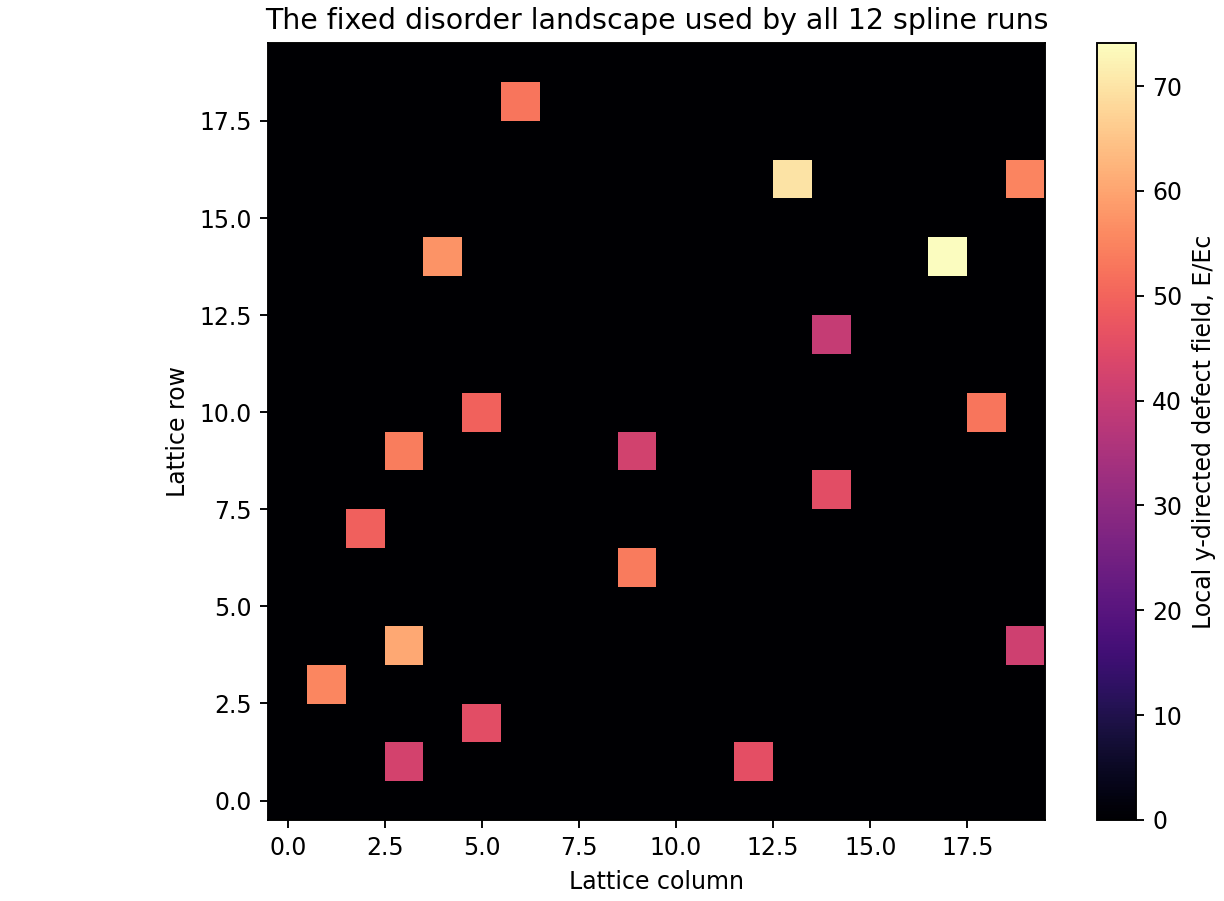

In [3]:
import representation as rep
from scipy.interpolate import BSpline
from reproduce import verify_sources
verify_sources()
assert rep.specification() == protocol['configuration']['representation']
coefficients = rep.full_coefficients(np.ones(rep.DIM))
example_spline = BSpline(rep.KNOTS, coefficients, rep.DEGREE)
assert np.allclose(example_spline([0., 1.]), 0., atol=1e-12, rtol=0)
assert np.allclose(example_spline.derivative()([0., 1.]), 0., atol=1e-12, rtol=0)
defects = np.load(ROOT / 'defect_list_seed.npy', allow_pickle=False).reshape(20, 20, 2)
nonzero = np.linalg.norm(defects, axis=-1) > 0
assert int(nonzero.sum()) == 19
print(f'{rep.DIM} free coordinates; {len(coefficients)} full coefficients; degree {rep.DEGREE}.')
print('Endpoint field and derivative checks passed. No amplitude clipping is applied.')
fig, ax = plt.subplots(figsize=(7.2, 5.3), constrained_layout=True)
shown = ax.imshow(defects[..., 1], origin='lower', cmap='magma')
ax.set(title='The fixed disorder landscape used by all 12 spline runs',
       xlabel='Lattice column', ylabel='Lattice row')
fig.colorbar(shown, ax=ax, label='Local y-directed defect field, E/Ec')
image_bytes = io.BytesIO()
fig.savefig(image_bytes, format='png', dpi=170)
display(Image(data=image_bytes.getvalue()))
plt.close(fig)

## 3. Recorded results or fresh simulation

Replay reads `data/baseline`. A fresh run calls the original numerical and
search modules with the explicitly recorded settings and writes under
`reproduction_runs/baseline`. The wrapper verifies source and defect hashes,
checks existing run identities, resumes only matching local checkpoints,
and skips already completed matching runs. It refuses protected destinations.

A complete new search uses 12,480 physical evaluations. Validation has its
own cost. Runtime depends on the machine; a one-generation portability
check of all four pipelines is included in the delivered evidence.

In [4]:
from reproduce import preflight, run_reproduction
new_search_queries = 0
new_validation_queries = 0
if RUN_SIMULATIONS:
    reproduction = run_reproduction(seeds=(0, 1, 2), generations=32, workers=WORKERS)
    RESULTS = Path(reproduction['plan']['output'])
    new_search_queries = reproduction['new_physical_search_evaluations']
    ANALYSIS_ROOT = ROOT / 'reproduction_runs/analysis'
else:
    RESULTS = ROOT / 'data/baseline'
    ANALYSIS_ROOT = ROOT
TABLES = ANALYSIS_ROOT / 'tables'
FIGURES = ANALYSIS_ROOT / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print('Reading:', RESULTS.relative_to(ROOT))
print('New search evaluations in this execution:', new_search_queries)

Reading: data/baseline
New search evaluations in this execution: 0


In [5]:
archive_audit = audit_histories(RESULTS, seeds=(0, 1, 2), generations=32)
display(pd.DataFrame(archive_audit['runs']))
display(pd.DataFrame(archive_audit['summary'].items(), columns=['Accounting item', 'Value']))

,method,seed,generations,available_observations,valid,unusable,native_component_guard_exclusions
0,ga_dkl,0,32,1088,1088,0,0
1,ga_dkl,1,32,1088,1087,1,1
2,ga_dkl,2,32,1088,1088,0,0
3,gflownet_dkl,0,32,1088,1088,0,0
4,gflownet_dkl,1,32,1088,1087,1,1
5,gflownet_dkl,2,32,1088,1088,0,0
6,diffusion_dkl,0,32,1088,1088,0,0
7,diffusion_dkl,1,32,1088,1087,1,1
8,diffusion_dkl,2,32,1088,1088,0,0
9,qd_dkl,0,32,1088,1088,0,0


,Accounting item,Value
0,runs,12
1,disorder_maps,1
2,search_seeds,3
3,archived_observations,13056
4,valid_archived_observations,13048
5,invalid_archived_observations,8
6,initial_physical_queries,192
7,adaptive_physical_queries,12288
8,physical_search_queries,12480
9,invalid_physical_queries,8


**Budget interpretation.** Every method receives 64 initial observations,
and its horizontal axis starts at a cost of 64. The initial design was
physically evaluated once per seed and reused across the four methods.
Thus the original archive has 13,056 rows but represents 12,480 physical
search attempts. All eight guard-excluded attempts still consume budget.

Later observations arrive in batches of 32. Primary efficiency curves
report the best available result **after each completed batch**. A row's
position inside a batch is recorded bookkeeping, not an adaptive decision.

In [6]:
if RUN_FULL_REVALIDATION:
    from validate_finalists import validate_finalists
    VALIDATION = ROOT / 'reproduction_runs' / ('validation' if RUN_SIMULATIONS else 'baseline_revalidation')
    validation_report = validate_finalists(RESULTS, VALIDATION)
    f2_count = len(validation_report['selected_candidates'])
    f4_count = sum('fidelity4' in c for c in validation_report['selected_candidates'])
    sweep_count = len(validation_report['amplitude_sweep'])
    new_validation_queries = f2_count + f4_count + sweep_count
    validation_ledger = {
        'fidelity_2_evaluations': f2_count, 'fidelity_4_evaluations': f4_count,
        'amplitude_sweep_evaluations': sweep_count,
        'new_physical_evaluations': new_validation_queries,
        'included_in_search_budget': False,
    }
    (VALIDATION / 'notebook_query_ledger.json').write_text(json.dumps(validation_ledger, indent=2) + '\n')
elif RUN_SIMULATIONS:
    VALIDATION = None
    print('Fresh validation is disabled; archived validation will not be attached to new search results.')
else:
    VALIDATION = ROOT / 'validation/baseline'
print('New validation evaluations in this execution:', new_validation_queries)

New validation evaluations in this execution: 0


## 4. Rebuild the complete analysis

The original analysis and figure modules are preserved. This cell reruns
them and adds batch-aware efficiency, target-attainment, provenance,
sensitivity, and exact control exports. Every displayed reward comes from
the simulator archive; none is a surrogate prediction.

In [7]:
import analyze_results
import plots
import notebook_analysis
with contextlib.redirect_stdout(io.StringIO()):
    original_analysis = analyze_results.main([
        '--results', str(RESULTS), '--output', str(TABLES / 'original'),
        '--expected-seeds', '0,1,2'])
    original_figures = plots.create_figures(RESULTS, FIGURES / 'original')
study = notebook_analysis.build_analysis(
    RESULTS, TABLES / 'study', FIGURES / 'study', validation_dir=VALIDATION,
    expected_seeds=(0, 1, 2), expected_generations=32)
if VALIDATION is not None:
    from plot_physics import create_physics_figures
    physics_figures = create_physics_figures(VALIDATION, FIGURES / 'physics')
print('Rebuilt measured-analysis tables and figures. Analysis itself spent 0 simulator queries.')

def show_figure(name, group='study', width=1100):
    display(Image(filename=str(FIGURES / group / (name + '.png')), width=width))

def table(name):
    return pd.read_csv(TABLES / 'study' / (name + '.csv'))

Rebuilt measured-analysis tables and figures. Analysis itself spent 0 simulator queries.


In [8]:
display(table('method_comparison')[[
    'method_label', 'best_curl', 'median_seed_best', 'min_seed_best', 'max_seed_best',
    'best_complexity', 'best_raw_turns', 'best_peak_Ec', 'best_proposal_source']])
print(f"Zero-drive curl: {study['zero_drive_curl']:.12f}")
print(f"Best observed curl: {study['best_observed_curl']:.12f}")
print(f"Improvement over zero drive: {study['best_improvement_over_zero_pct']:.6f}%")

Zero-drive curl: 10.447895713354
Best observed curl: 11.906135760735
Improvement over zero drive: 13.957261%


,method_label,best_curl,median_seed_best,min_seed_best,max_seed_best,best_complexity,best_raw_turns,best_peak_Ec,best_proposal_source
0,GA–DKL,11.906135761,11.903156567,11.902688915,11.906135761,13,19,42.483464610,method_proposer
1,GFlowNet–DKL,11.898480148,11.893783947,11.890163919,11.898480148,1,1,7.945213618,common_prior
2,Guided diffusion–DKL,11.898480148,11.893783947,11.890163919,11.898480148,1,1,7.945213618,common_prior
3,Quality diversity–DKL,11.905000767,11.904050069,11.903407886,11.905000767,17,22,21.532453251,method_proposer


The best-of-three result describes the most successful run. The median
and range describe three optimizer seeds, not a confidence interval or
three disorder realizations. These are four implemented search pipelines
sharing one simulator and one DKL family.

The GA and QD champions originated from their own generators. In the
archived spline study, GFlowNet and diffusion have identical champions for
each paired seed; all were proposed by the shared exploration prior and
selected by DKL. Their successful scores therefore cannot be attributed
to the learned generators alone.

## 5. Reward versus experimental evaluations

The first figure shows both total curl and the fraction of the pooled
observed gain achieved:

\[
g(R) = \frac{R-R_0}{R_{\rm best,observed}-R_0}.
\]

Lines summarize three seeds at matched completed-batch costs. Seed ranges
are descriptive. The pooled best is a **posthoc reference**, not a known
global optimum and not the performance of one run with a smaller budget.

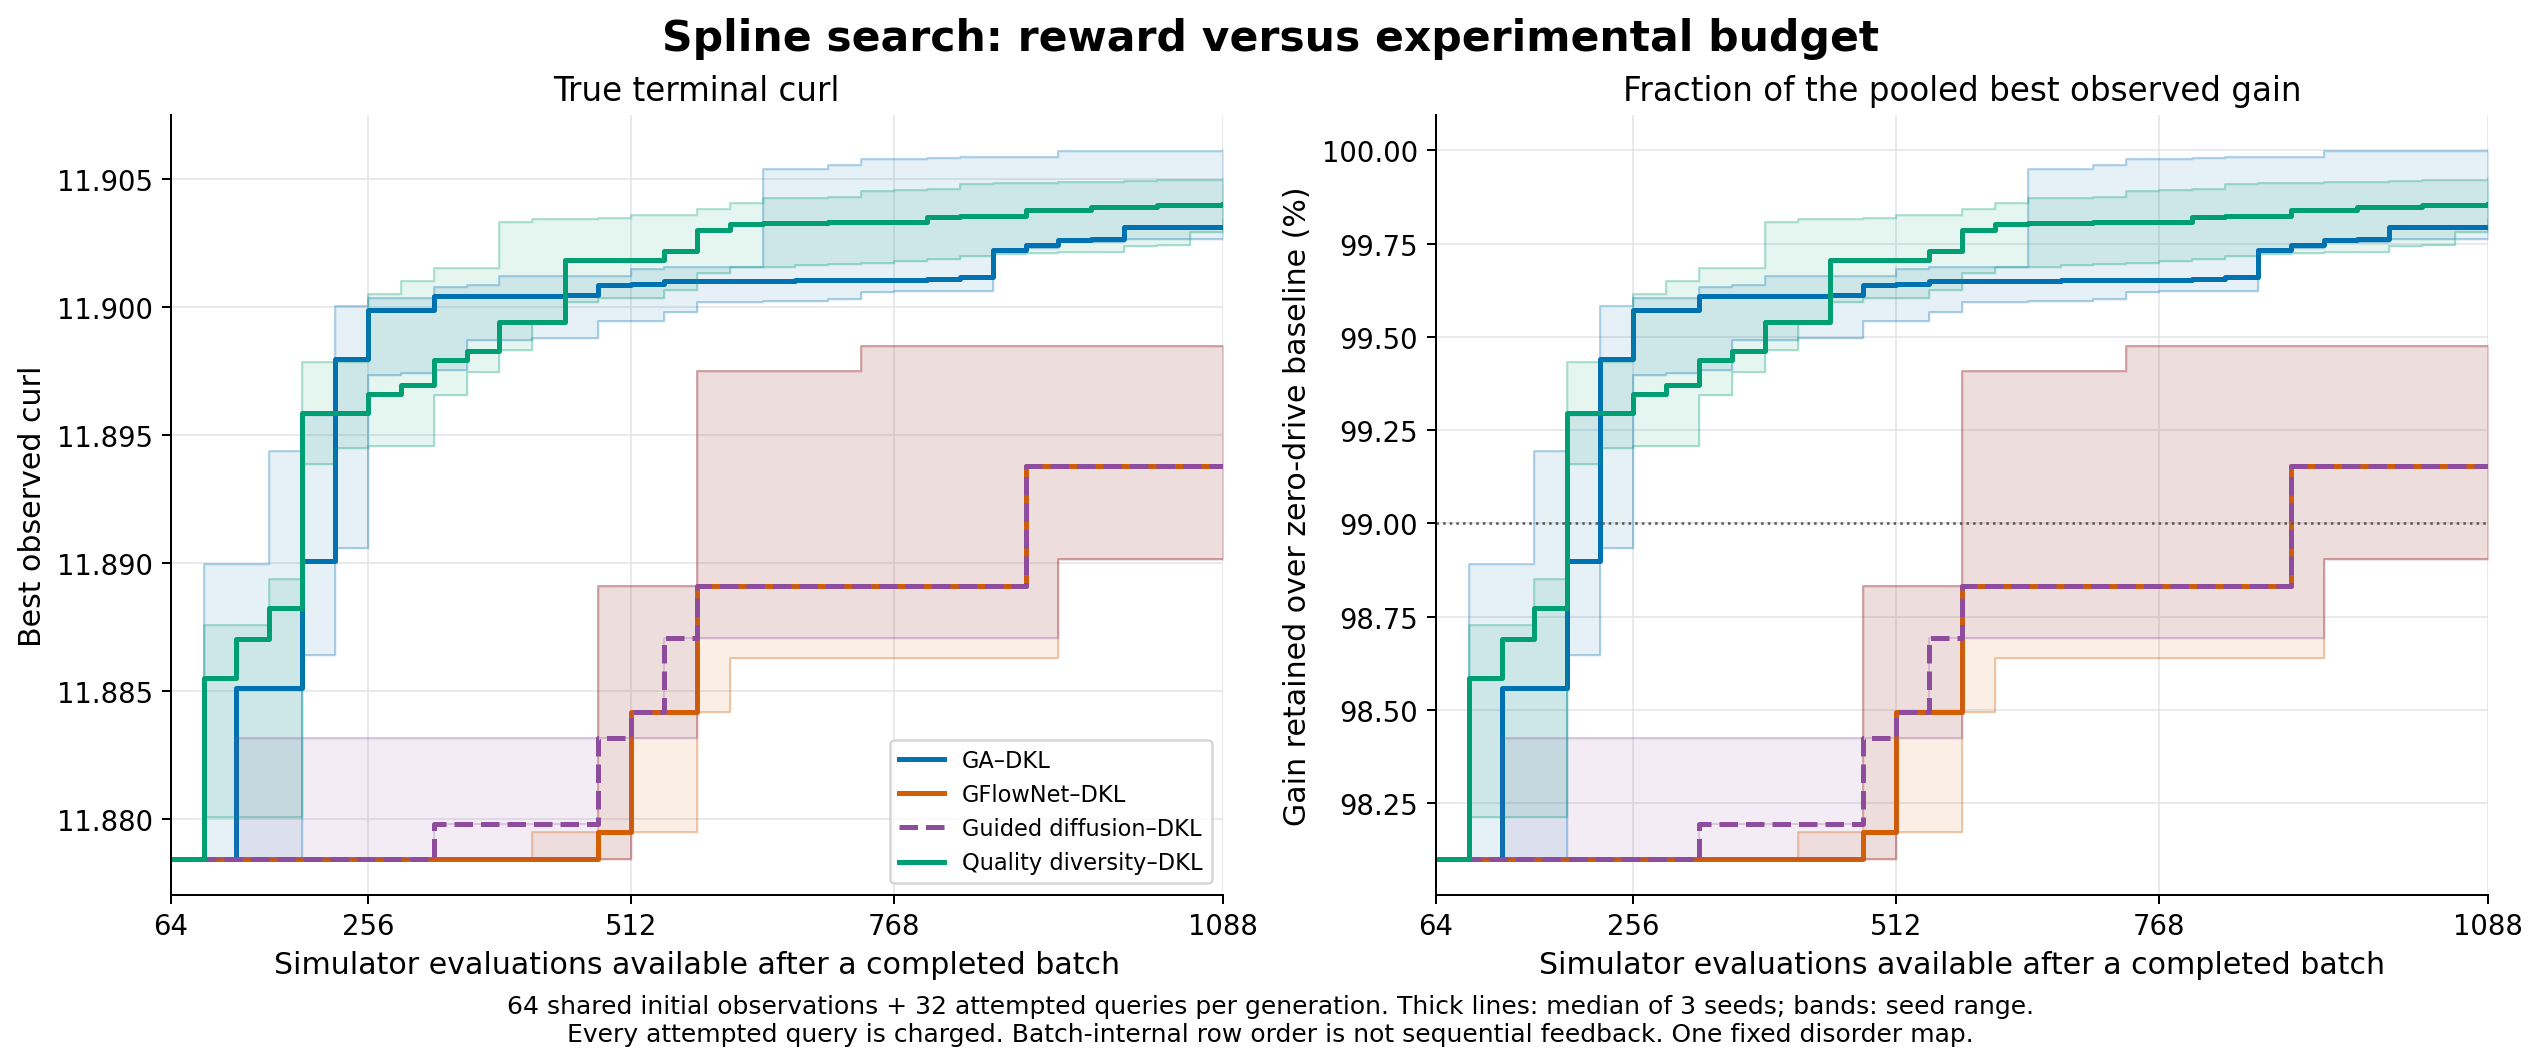

,method,gain_fraction_target,runs,reached,not_reached,conditional_median_evaluations,conditional_min_evaluations,conditional_max_evaluations
0,ga_dkl,0.950,3,3,0,64.0,64.0,64.0
1,ga_dkl,0.990,3,3,0,224.0,160.0,256.0
2,ga_dkl,0.999,3,1,2,640.0,640.0,640.0
3,gflownet_dkl,0.950,3,3,0,64.0,64.0,64.0
4,gflownet_dkl,0.990,3,2,1,736.0,576.0,896.0
5,gflownet_dkl,0.999,3,0,3,NaN,NaN,NaN
6,diffusion_dkl,0.950,3,3,0,64.0,64.0,64.0
7,diffusion_dkl,0.990,3,2,1,736.0,576.0,896.0
8,diffusion_dkl,0.999,3,0,3,NaN,NaN,NaN
9,qd_dkl,0.950,3,3,0,64.0,64.0,64.0


In [9]:
show_figure('spline_evaluation_efficiency')
display(table('query_target_summary')[[
    'method', 'gain_fraction_target', 'runs', 'reached', 'not_reached',
    'conditional_median_evaluations', 'conditional_min_evaluations',
    'conditional_max_evaluations']])

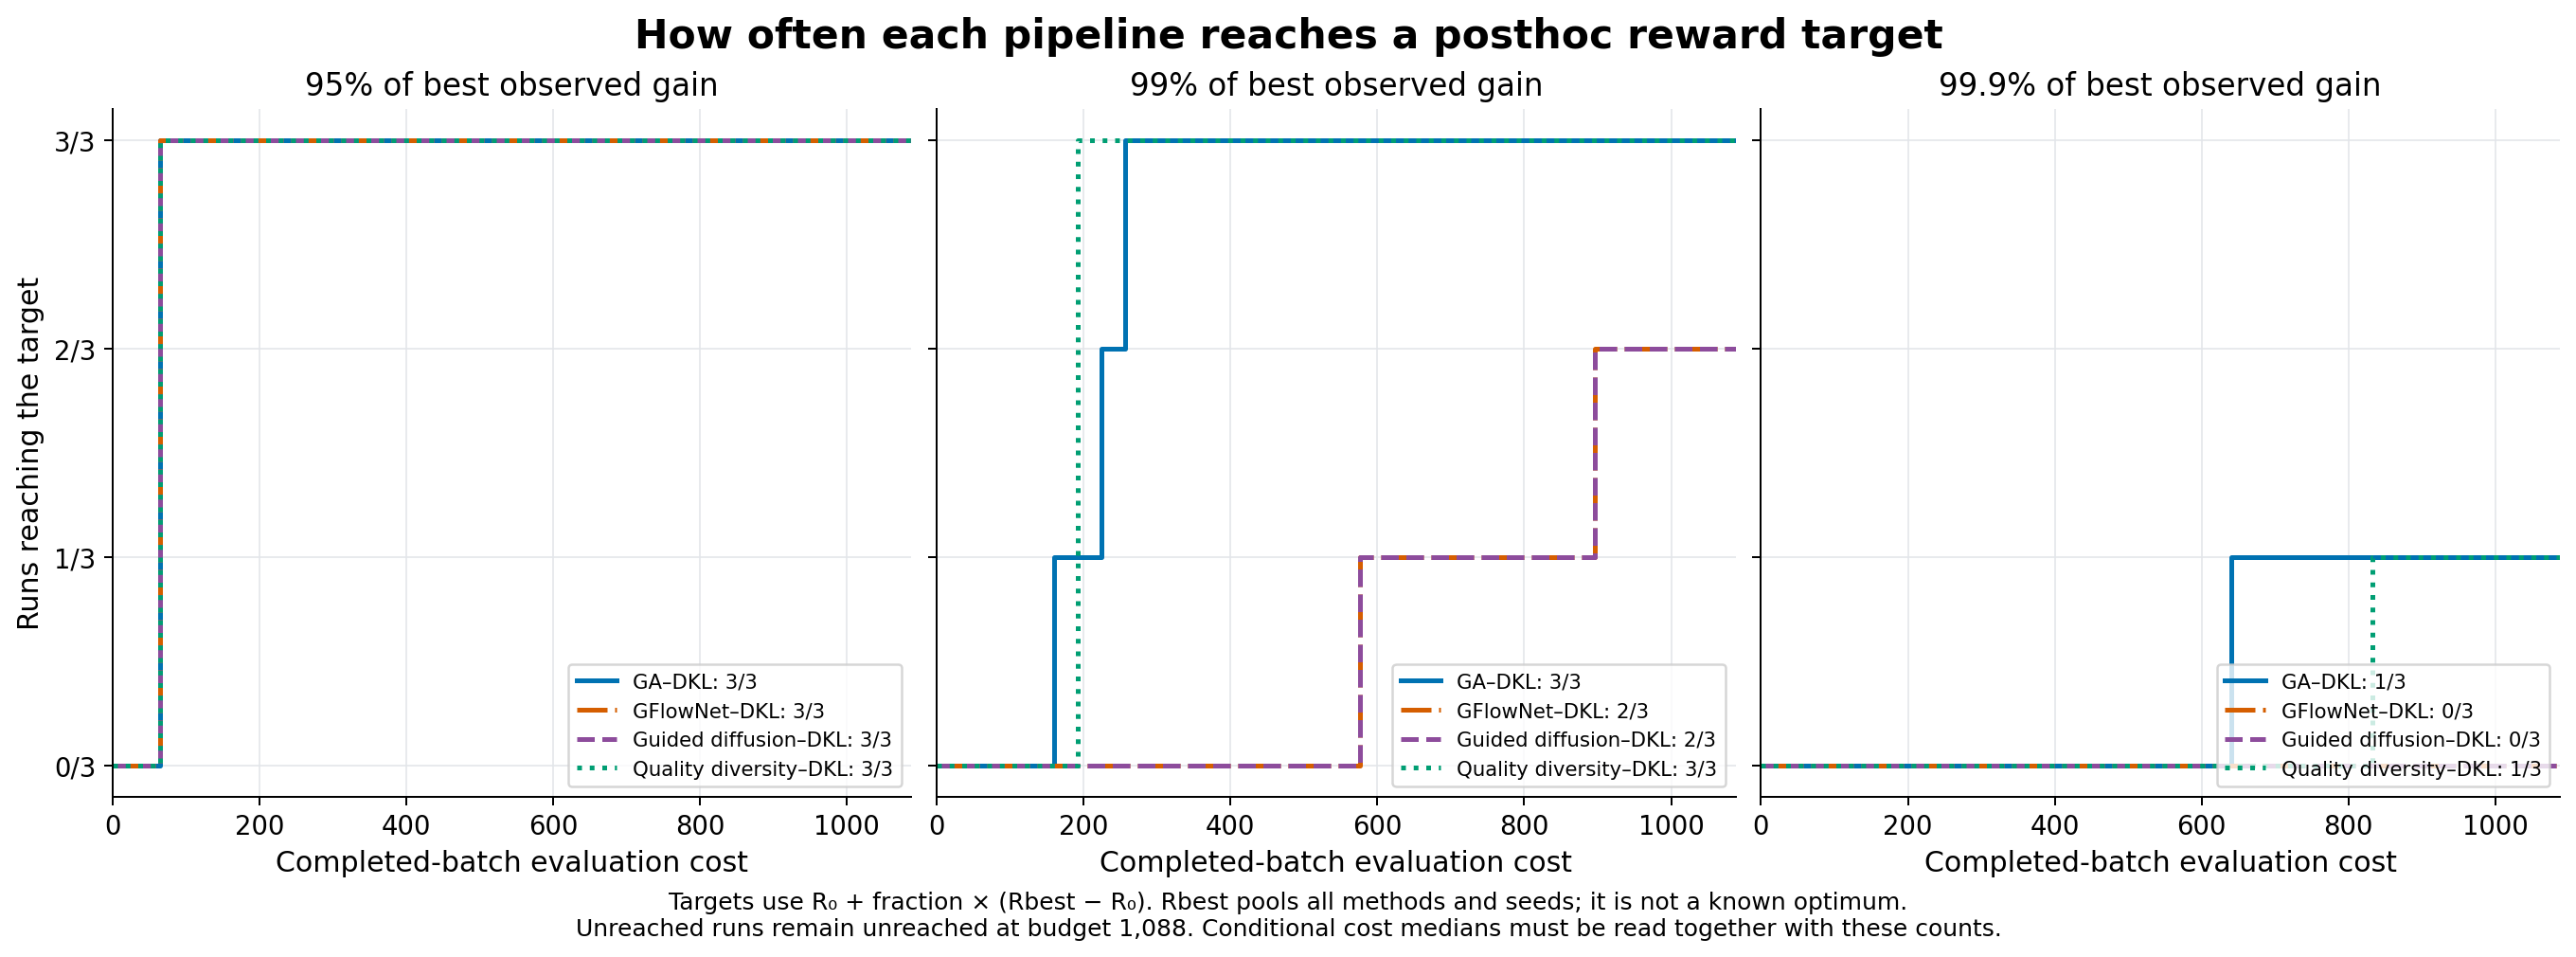

In [10]:
show_figure('spline_target_attainment')

A conditional cost median excludes unsuccessful runs, so it must be read
together with the reach count. All methods already reach 95% of the pooled
observed gain during initialization. In the archived study, 99% of gain
is reached by all three GA and QD runs, but only two of three GFlowNet and
diffusion runs. The exported per-run table retains the unreached outcomes.

## 6. Complexity–reward Pareto fronts over all generations

A control is nondominated when no observed valid control has at least as
much curl and at most as many turns, with a strict improvement in one of
those quantities. These are empirical fronts over the **entire** archive.
Early controls remain eligible after later generations finish.

In the original scatter figures, colors identify the generation when a
candidate was evaluated. Generation 0 is initialization; generations 1–4
have distinct colors, followed by the later-generation palette. Black
lines join observed nondominated points and do not assert feasible
interpolation between them.

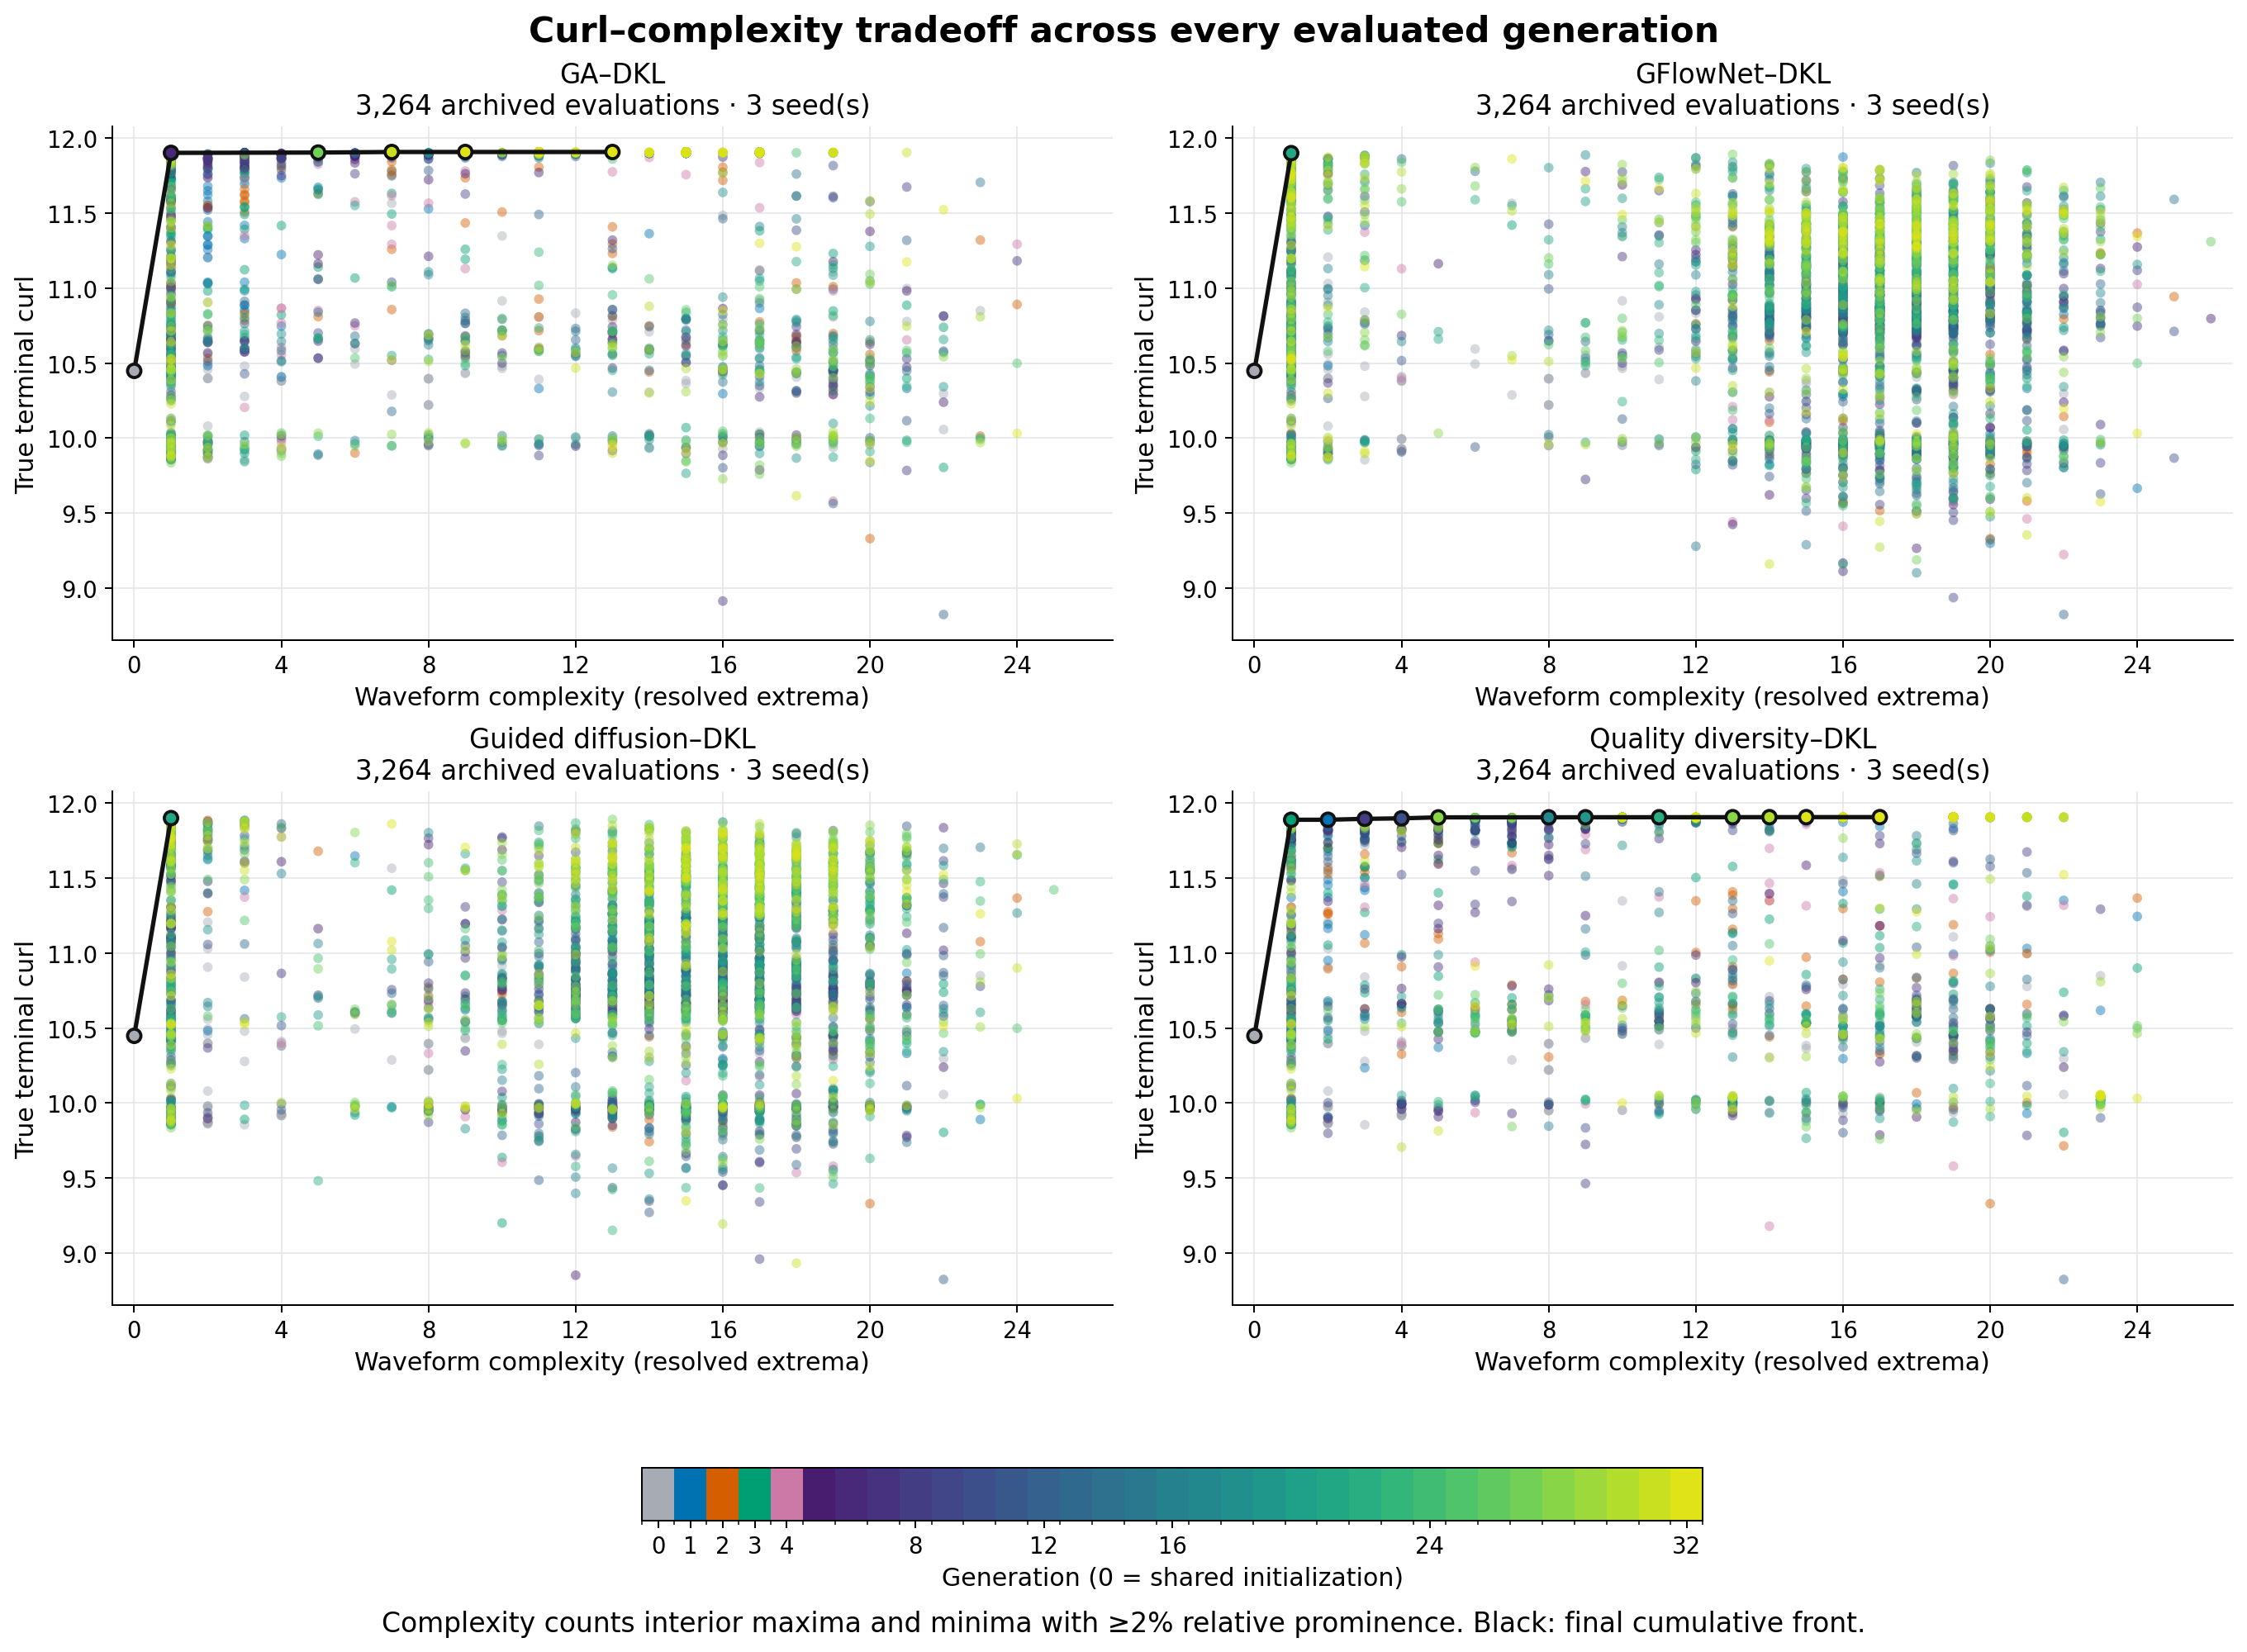

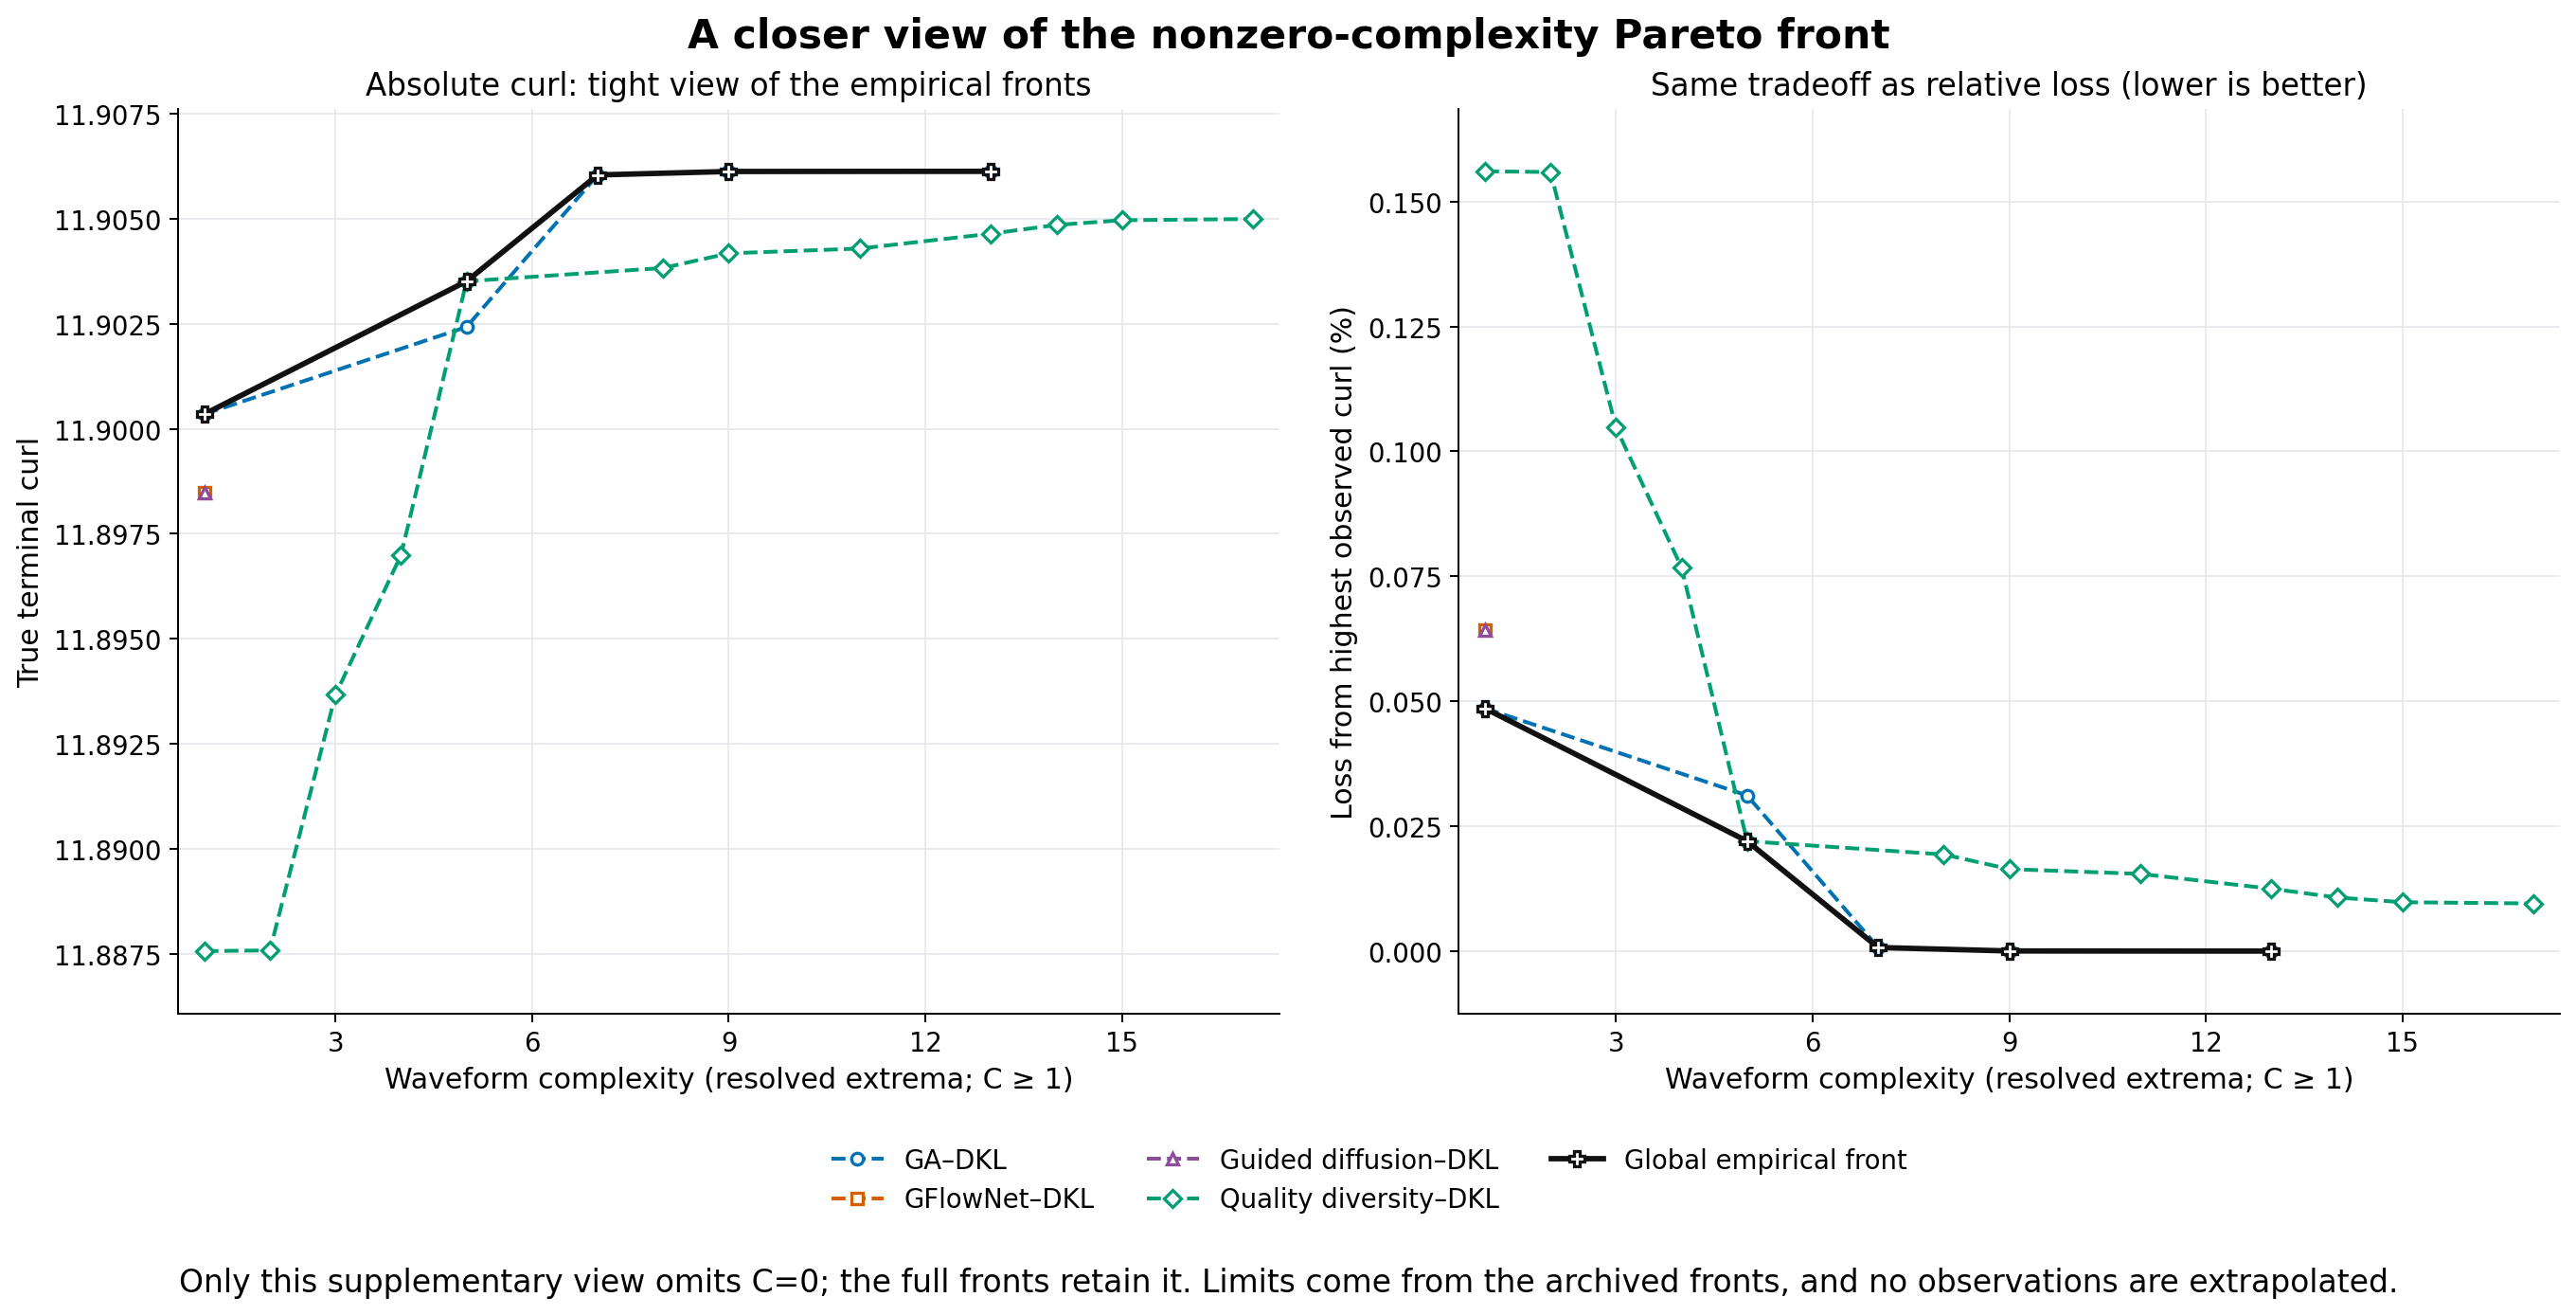

In [11]:
show_figure('pareto_by_method', group='original')
show_figure('pareto_high_curl_zoom', group='original')

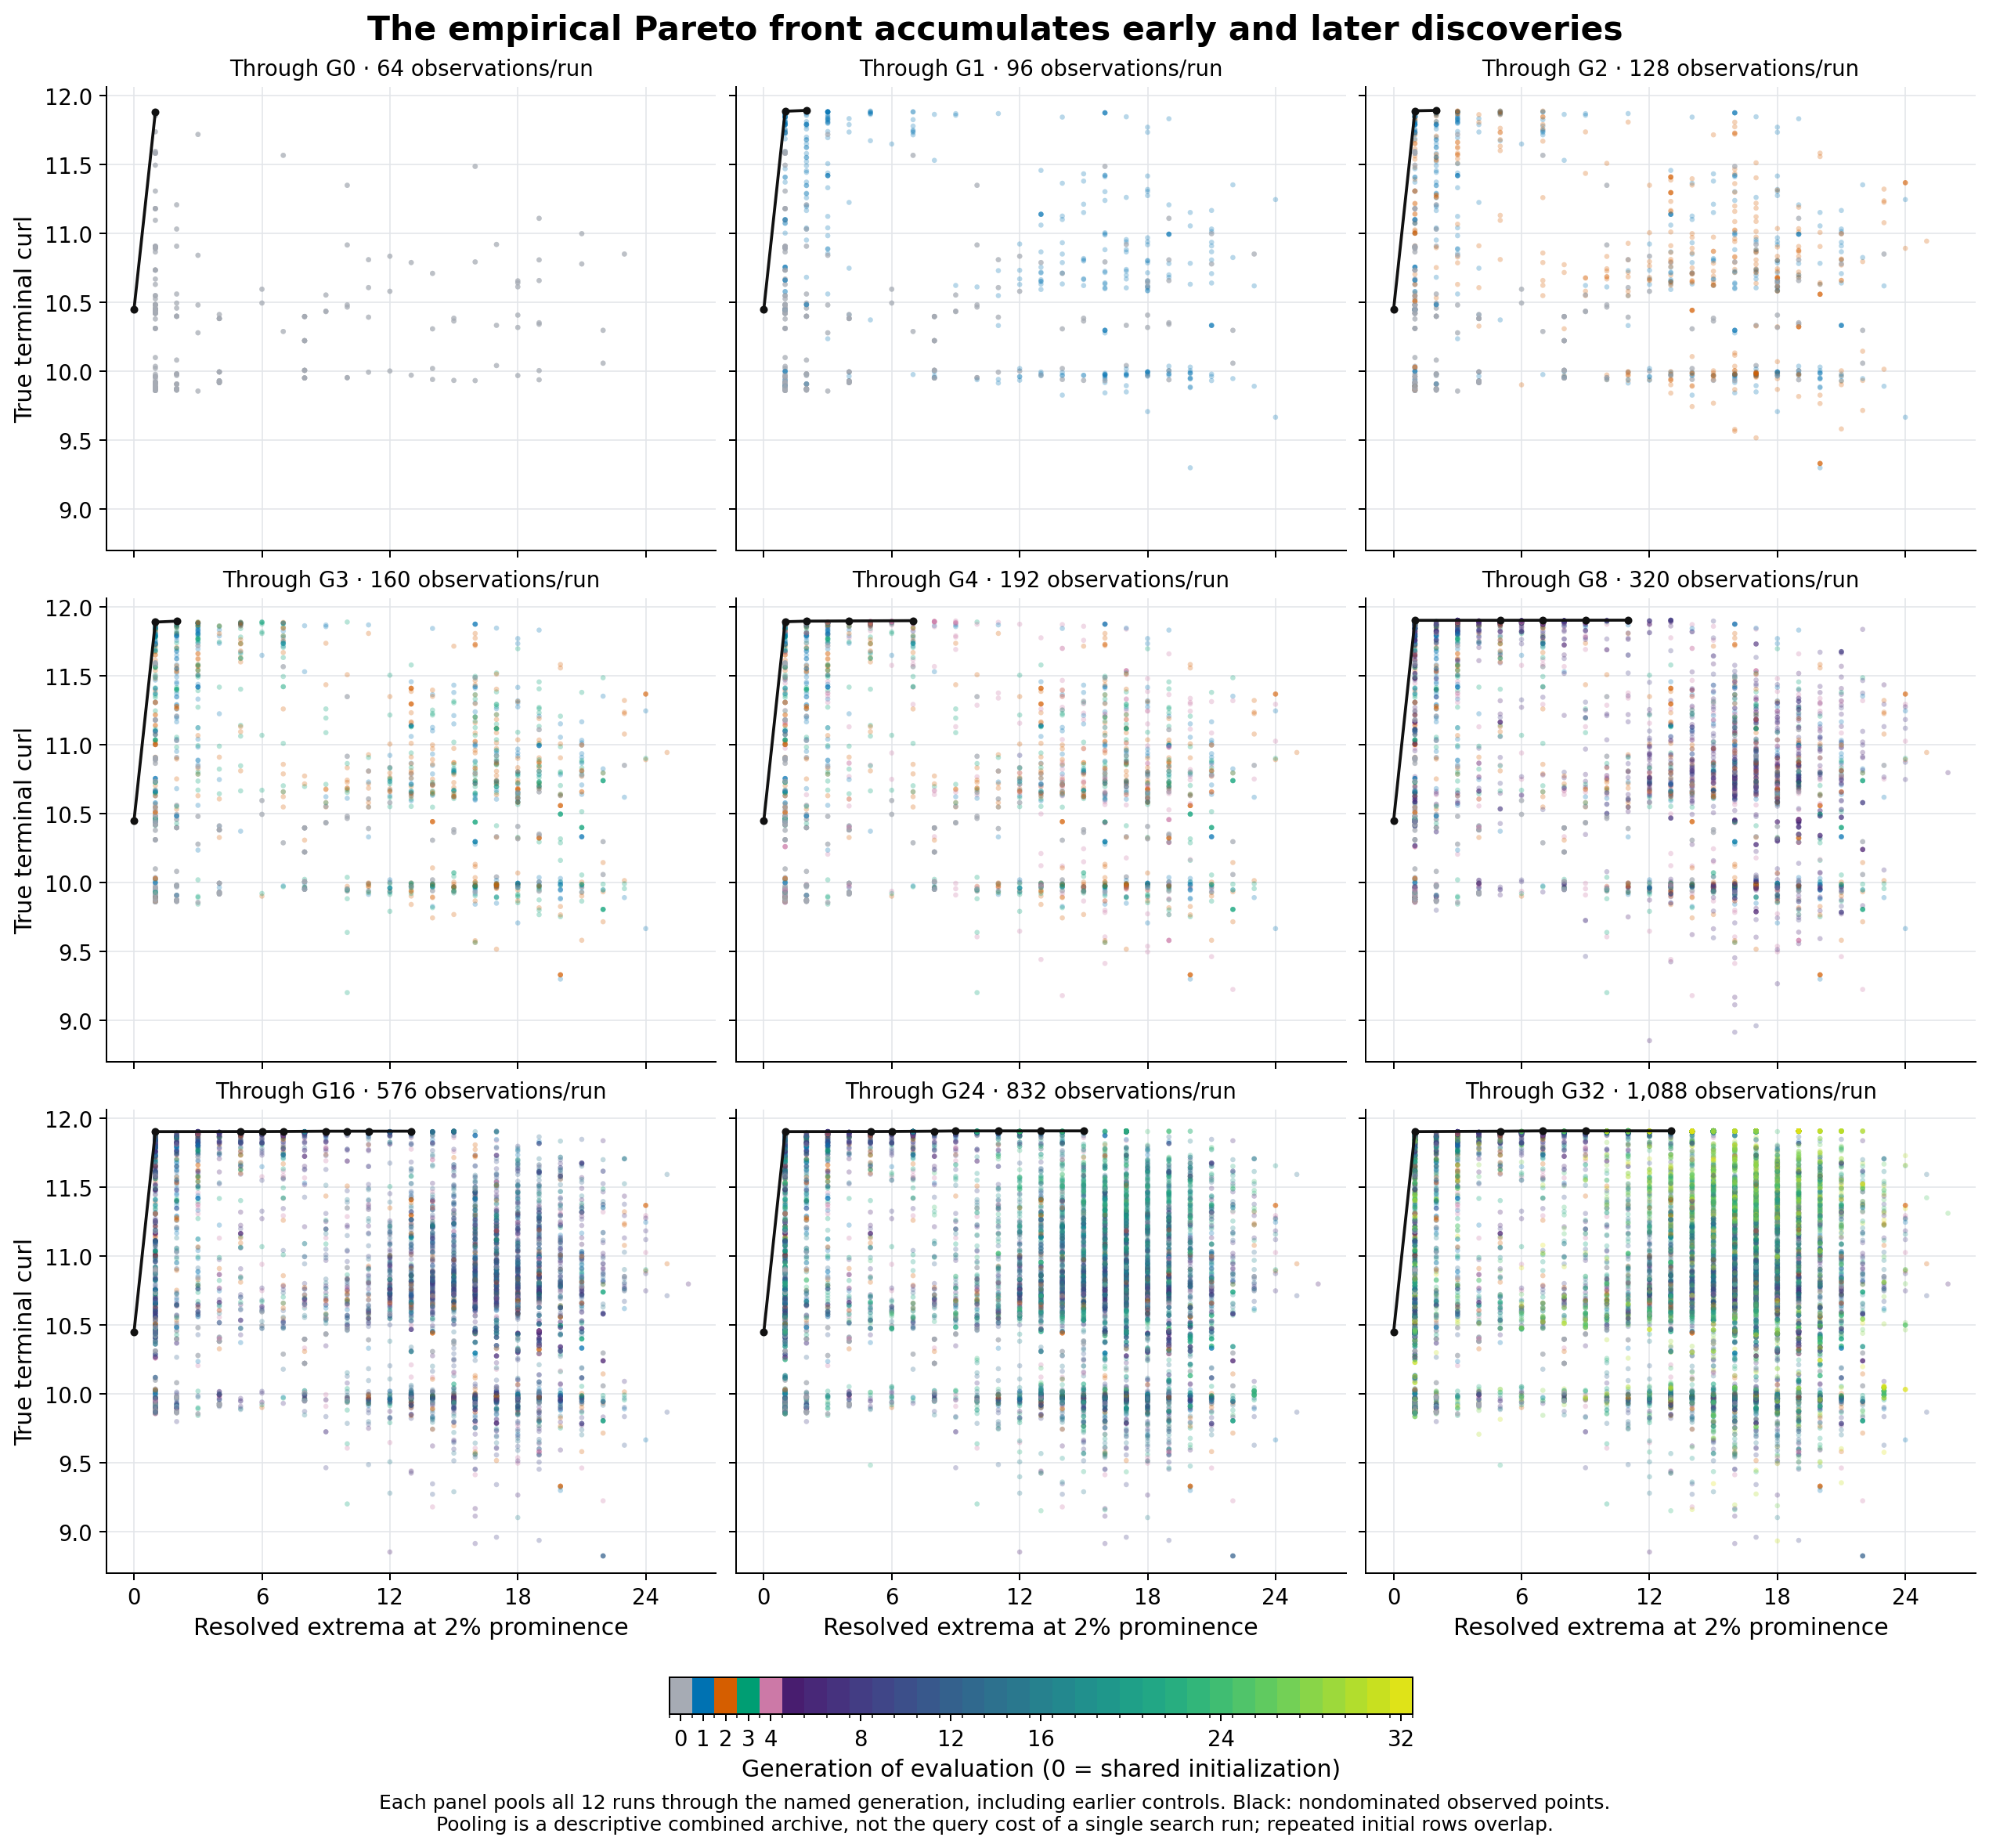

,complexity,raw_turns,curl,method,seed,generation,proposal_source
0,0,0,10.447895713,ga_dkl,0,0,initial_design
1,1,1,11.900352297,ga_dkl,0,6,method_proposer
2,5,13,11.903516526,qd_dkl,1,28,method_proposer
3,7,12,11.906049832,ga_dkl,0,31,method_proposer
4,9,17,11.906132659,ga_dkl,0,32,method_proposer
5,13,19,11.906135761,ga_dkl,0,32,method_proposer


In [12]:
show_figure('spline_front_history_snapshots')
front = table('pooled_historical_front')
wanted = ['complexity', 'raw_turns', 'curl', 'method', 'seed', 'generation',
          'peak_Ec', 'proposal_source']
display(front[[column for column in wanted if column in front.columns]])

### How much does the turn definition matter?

A two-percent-resolved turn count can ignore small ripples. The raw count
detects every sampled extremum. The next plot rebuilds the pooled fronts
for raw, 1%, 2%, and 5% prominence definitions. Selected controls are also
reconstructed on 8,193 samples. The best simple pulse in the archived study has
**one turn under all four definitions**; its simplicity is not an effect
of the prominence threshold.

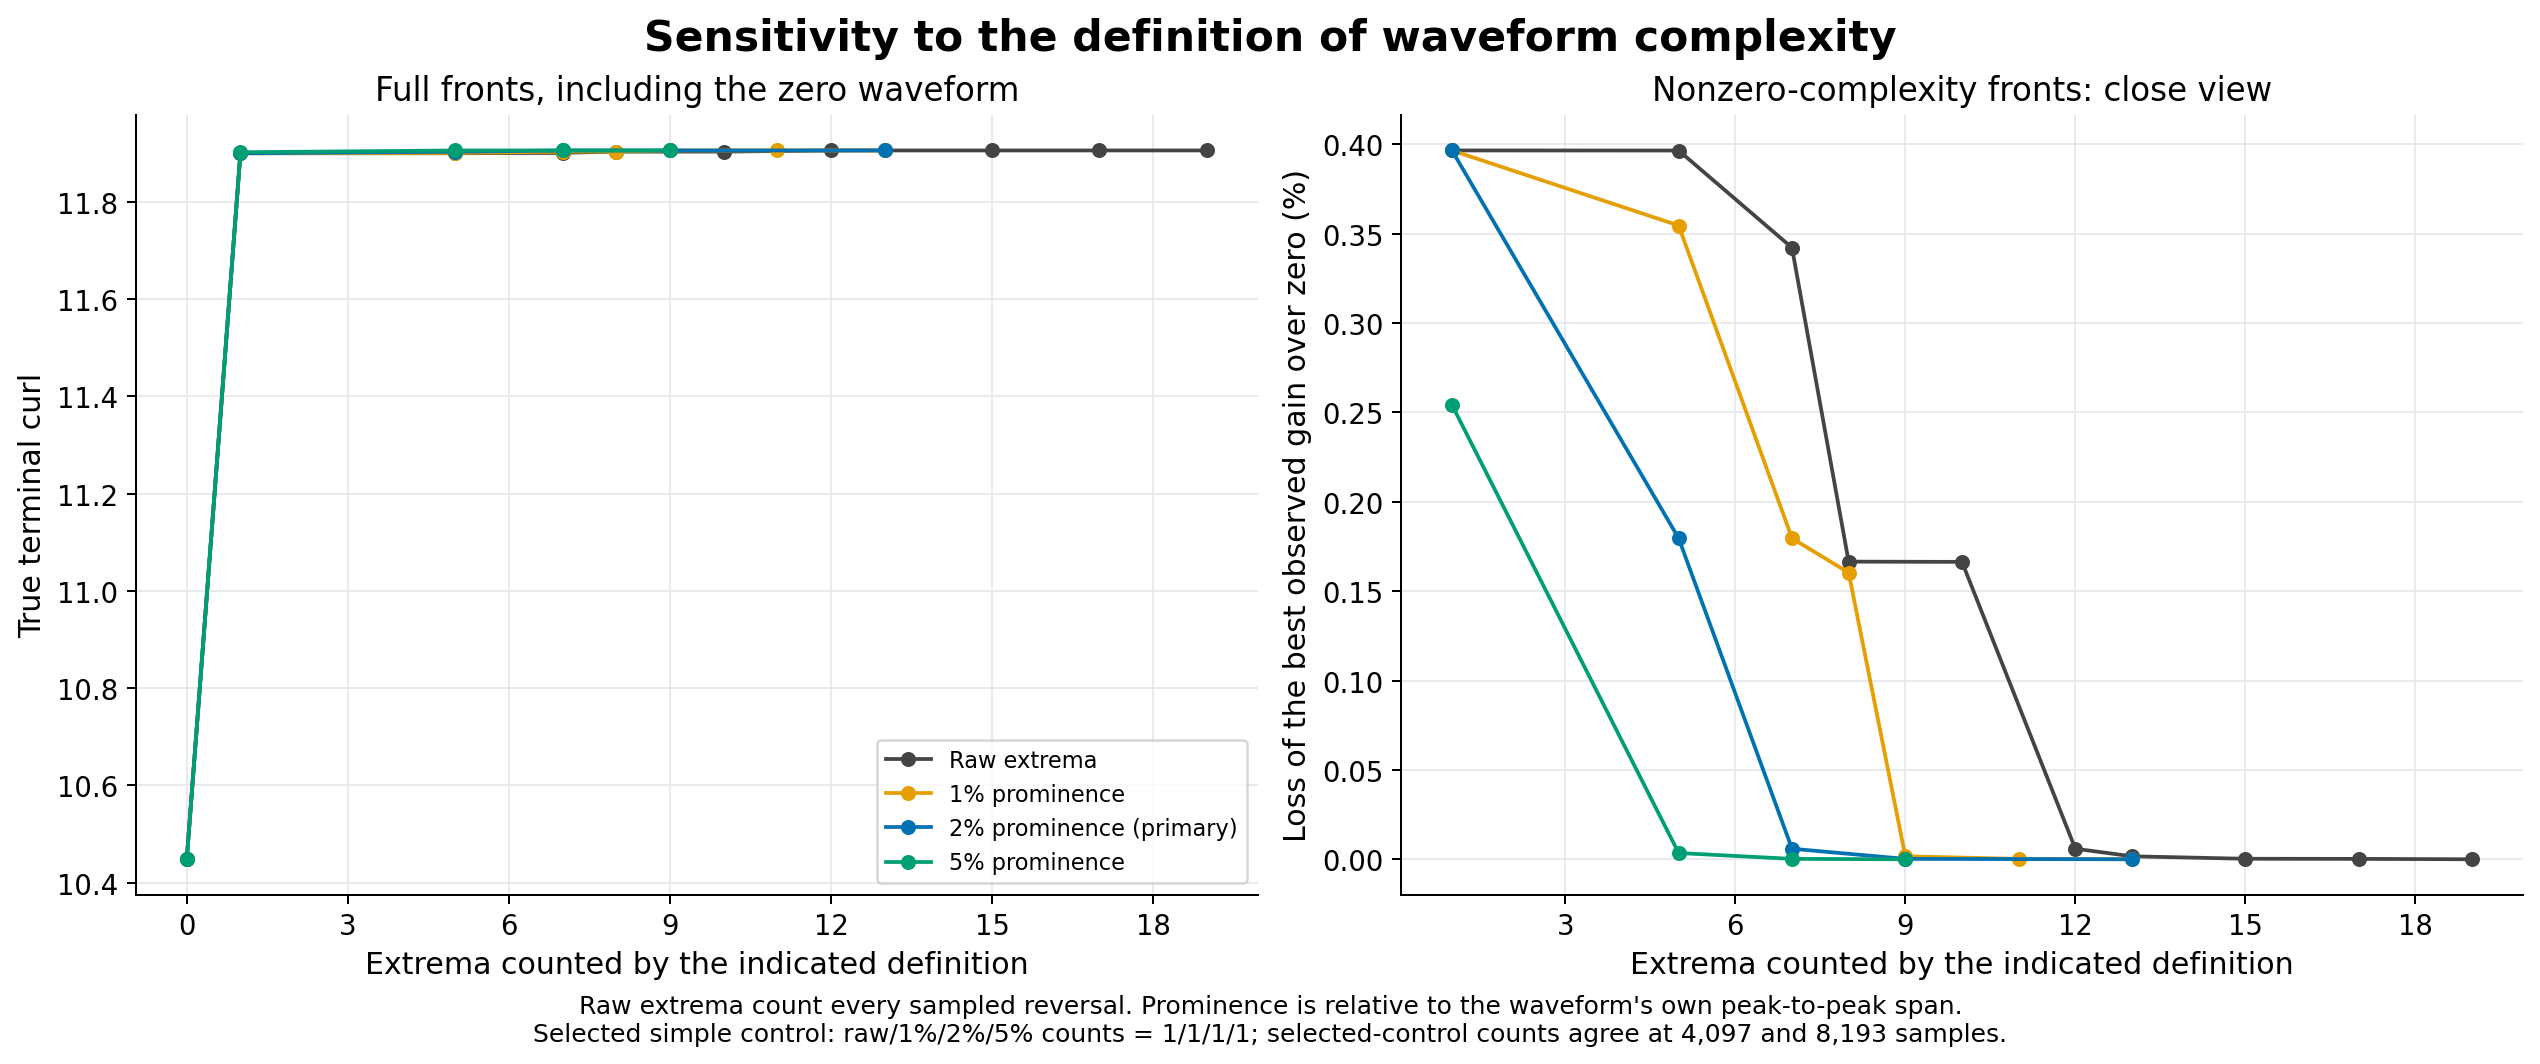

In [13]:
show_figure('spline_complexity_sensitivity')

## 7. Construct the highest-curl and simple waveforms

The simple selection minimizes observed complexity among controls with
\(R\ge 0.999R_{\rm best,observed}\), then chooses the largest reward at that
complexity. **99.9% of total reward** differs from **99.9% of the gain over
zero drive**. Both retained fractions are reported below.

Actual field amplitudes are shown in E/Ec. The following cell reconstructs
the full driving waveform directly from the exported knot vector and
coefficients, appends the common zero-field hold, and compares it to the
archived renderer. It does not evaluate the simulator.

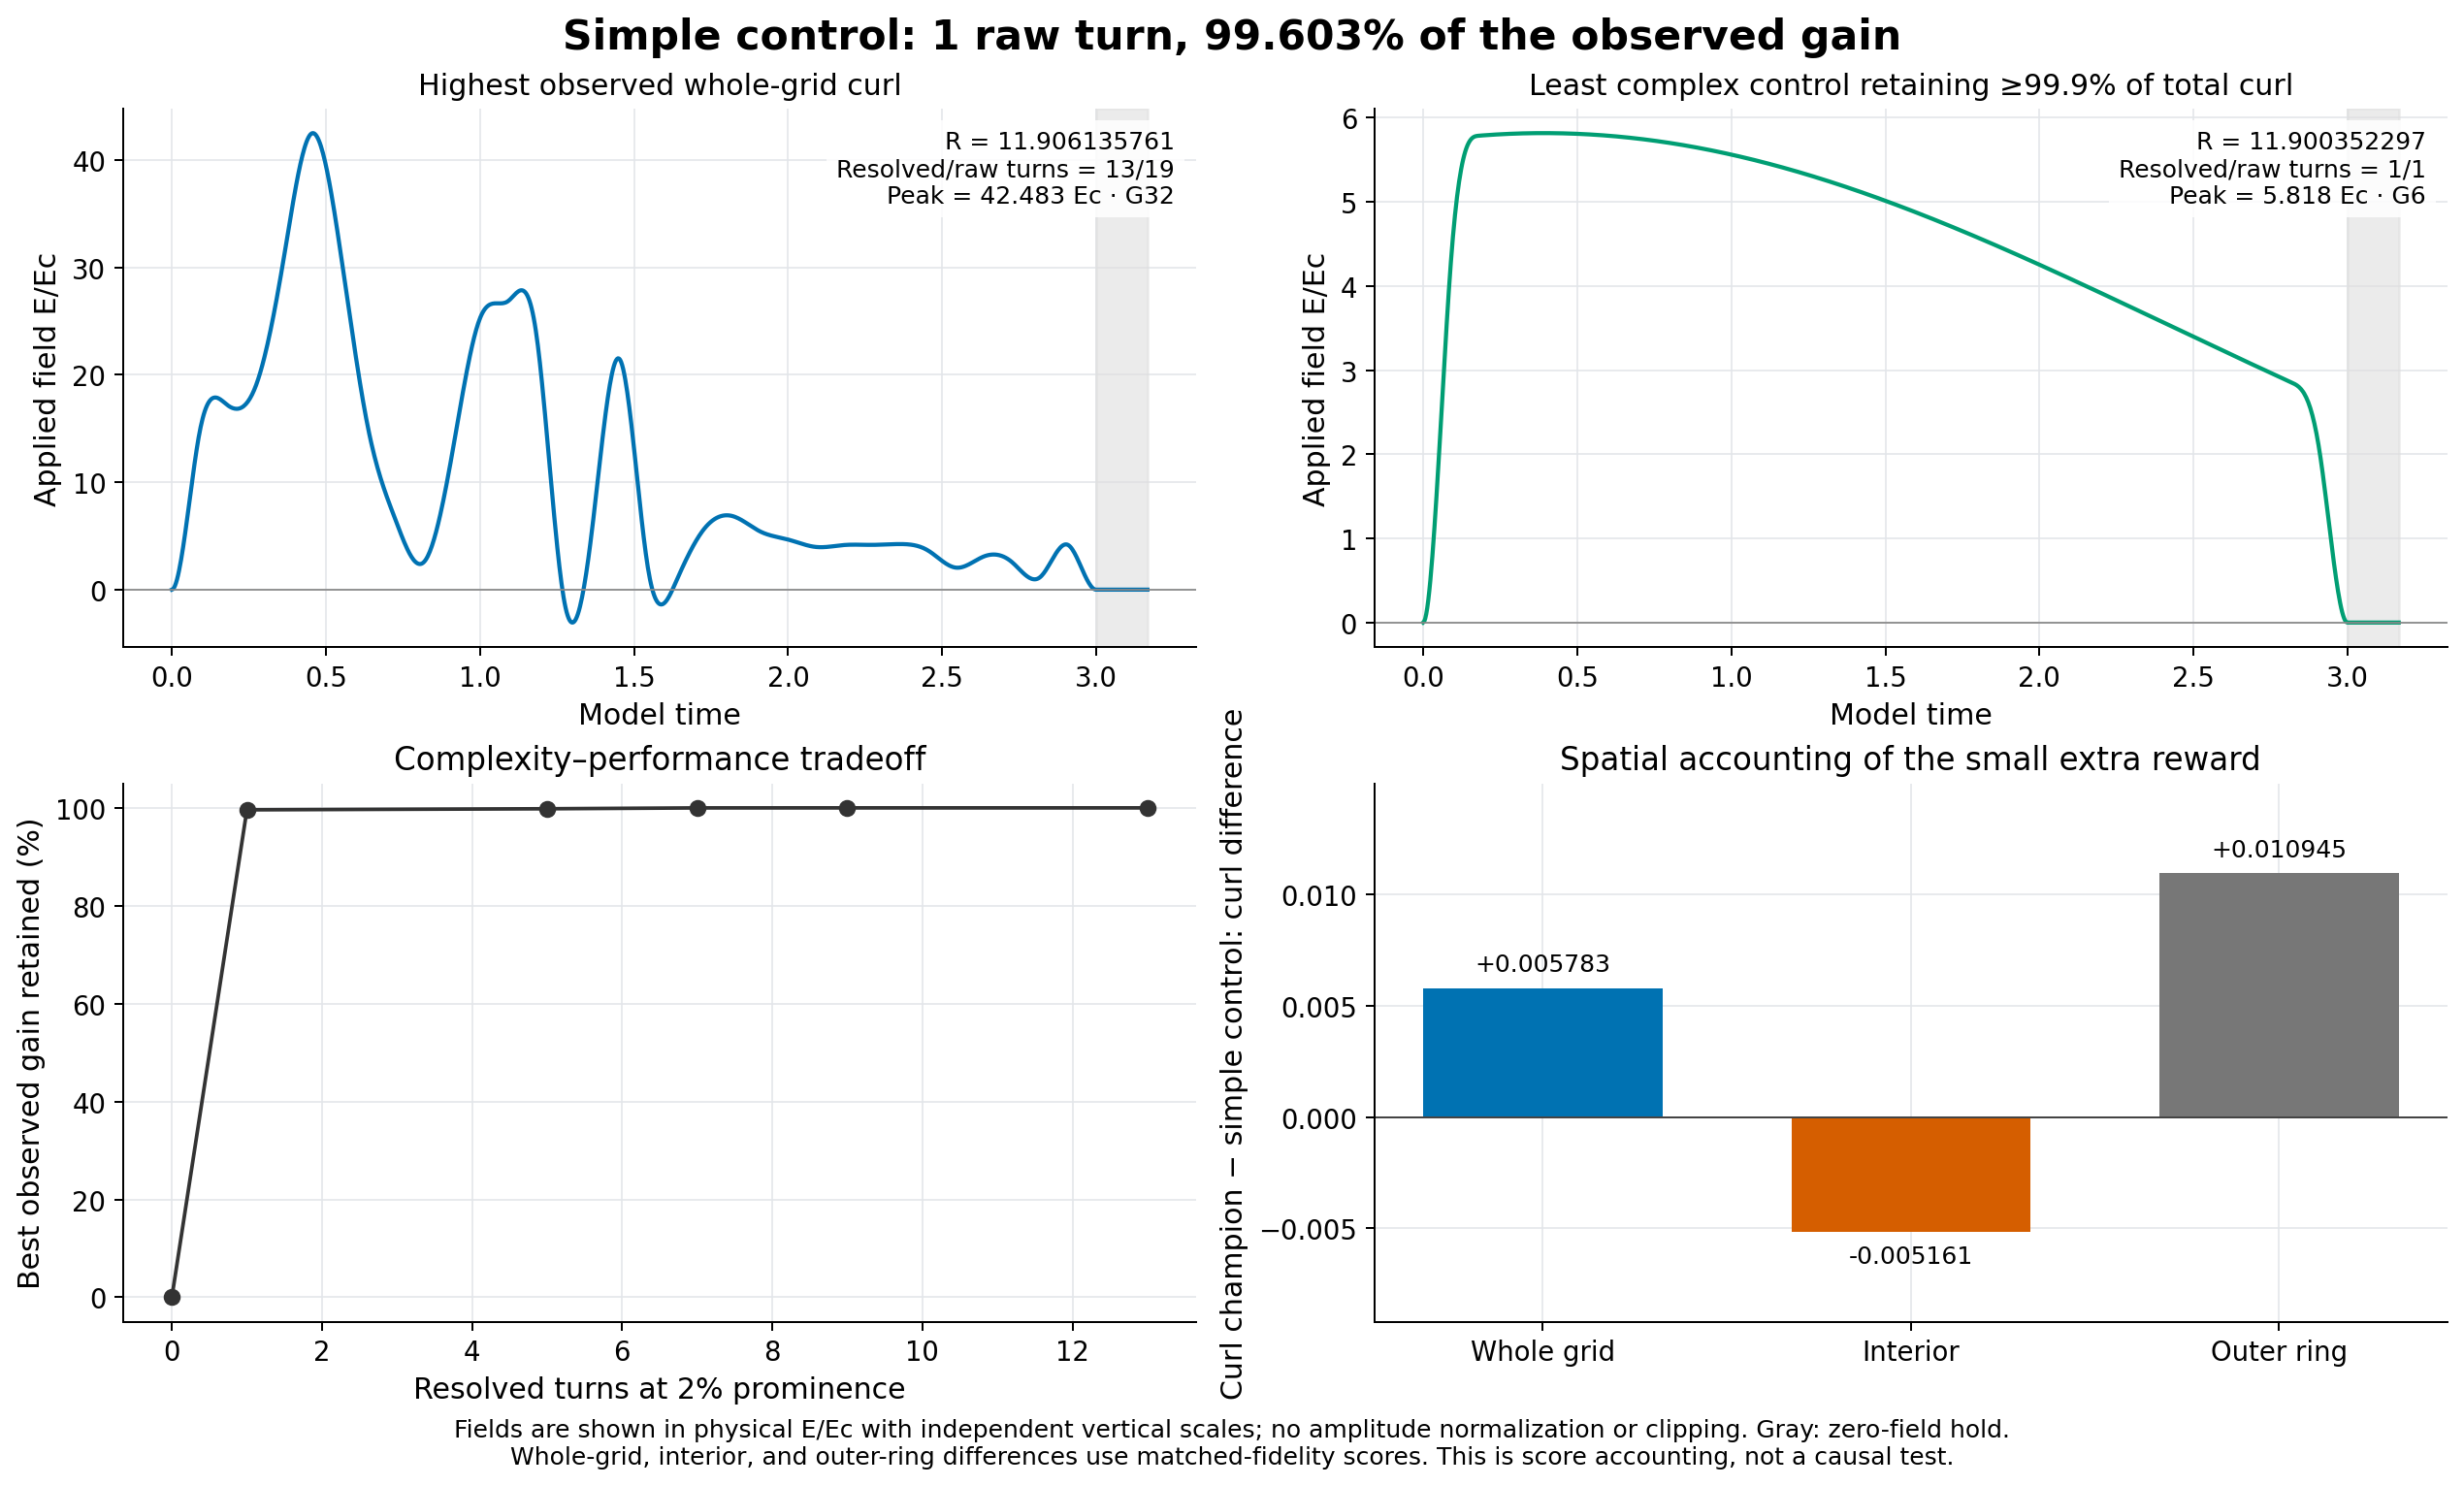

,role,method,seed,generation,curl,interior,complexity,raw_turns,turns_1pct,turns_5pct,peak_Ec,gain_fraction_retained,total_reward_fraction_retained
0,global_best,ga_dkl,0,32,11.906135761,9.577377439,13,19,13,9,42.483464610,1.000000000,1.000000000
1,simplest_99_9pct_total,ga_dkl,0,6,11.900352297,9.582538632,1,1,1,1,5.817977358,0.996033943,0.999514245


In [14]:
show_figure('spline_best_and_simple')
selected = table('selected_controls')
display(selected.loc[selected.role.isin(['global_best', 'simplest_99_9pct_total']), [
    'role', 'method', 'seed', 'generation', 'curl', 'interior', 'complexity',
    'raw_turns', 'turns_1pct', 'turns_5pct', 'peak_Ec',
    'gain_fraction_retained', 'total_reward_fraction_retained']])

In [15]:
controls_export = json.loads((TABLES / 'study/selected_controls.json').read_text())
role = 'simplest_99_9pct_total'  # Change to 'global_best' to reconstruct the curl champion.
control = controls_export['controls'][role]
waveform_function = BSpline(control['knots'], control['full_spline_coefficients_Ec'], control['degree'])
drive = waveform_function(np.linspace(0., 1., 900))
waveform = np.r_[drive, np.zeros(50)]
reference = rep.fields(np.asarray(control['free_coefficients_x']), n=900)
assert np.allclose(drive, reference, rtol=1e-13, atol=1e-12)
assert np.allclose(waveform_function([0., 1.]), 0., rtol=0, atol=1e-12)
assert np.allclose(waveform_function.derivative()([0., 1.]), 0., rtol=0, atol=1e-10)
reconstructed = pd.DataFrame({'time_model_units': rep.TIME, 'field_E_over_Ec': waveform,
                              'is_zero_hold': np.arange(len(rep.TIME)) >= 900})
reconstructed.to_csv(TABLES / 'study/reconstructed_selected_waveform.csv', index=False, float_format='%.17g')
print('Reconstructed:', role)
print('Exact coefficients and knots: tables/study/selected_controls.json')
print('All selected waveforms: tables/study/selected_waveforms.csv')
display(reconstructed.iloc[[0, 1, 449, 898, 899, 900, 949]])

Reconstructed: simplest_99_9pct_total
Exact coefficients and knots: tables/study/selected_controls.json
All selected waveforms: tables/study/selected_waveforms.csv


,time_model_units,field_E_over_Ec,is_zero_hold
0,0.000000000,0.000000000,False
1,0.003336113,0.011422401,False
449,1.497914929,5.016507849,False
898,2.995829858,0.005364577,False
899,2.999165972,0.000000000,False
900,3.002502085,0.000000000,True
949,3.165971643,0.000000000,True


## 8. Spatial accounting and numerical validation

Whole-grid curl equals interior plus outer-ring curl. Comparing the two
selected controls at the **same search fidelity** makes the role of the
objective explicit. In the original study, the complex winner's extra
whole-grid curl is accompanied by lower interior curl. Its perimeter
increase more than offsets that interior decrease. This is a decomposition
of the measured reward, not a causal test of boundary artifacts.

In [16]:
display(pd.DataFrame(study['complex_vs_simple_spatial_accounting'].items(),
                     columns=['Complex winner minus simple control', 'Curl difference']))
if VALIDATION is not None:
    validation_record = json.loads((VALIDATION / 'finalist_validation.json').read_text())
    display(pd.DataFrame(validation_record['checks'].items(), columns=['Validation check', 'Result']))
    print('Validated distinct controls:', validation_record['selection']['unique_selected_waveforms'])
else:
    print('No validation results attached to this fresh run; enable RUN_FULL_REVALIDATION to generate them.')

Validated distinct controls: 25


,Complex winner minus simple control,Curl difference
0,complex_minus_simple_whole_grid,0.005783463
1,complex_minus_simple_interior,-0.005161193
2,complex_minus_simple_outer_ring,0.010944656


,Validation check,Result
0,all_fidelity2_valid,True
1,all_fidelity2_within_native_guard,True
2,all_complexity_grid_counts_match,True
3,all_archived_complexity_counts_match,True
4,all_archive_reward_refinements_pass,True
5,all_winner_fidelity2_vs4_checks_pass,True
6,max_abs_curl_change_from_archive,0.0
7,sweep_all_valid,True
8,sweep_native_guard_exceeded_count,0


The recorded verification refines 25 distinct selected controls at fidelity
2, three distinct method-winning controls at fidelity 4, and 12 scaled
amplitudes of the winner. These 40 evaluations are separate from search.
GFlowNet and diffusion share a winner and therefore reuse its refinement.

All original refinement checks passed. The largest absolute change from
search to fidelity 2 was approximately 1.25 × 10⁻¹⁰. Selected 4,097- and
8,193-sample complexity counts agreed. Earlier native-Euler equivalence
evidence is retained in `validation/components/oracle_validation.json`;
the runnable optimizer uses the documented RK4 discretization.

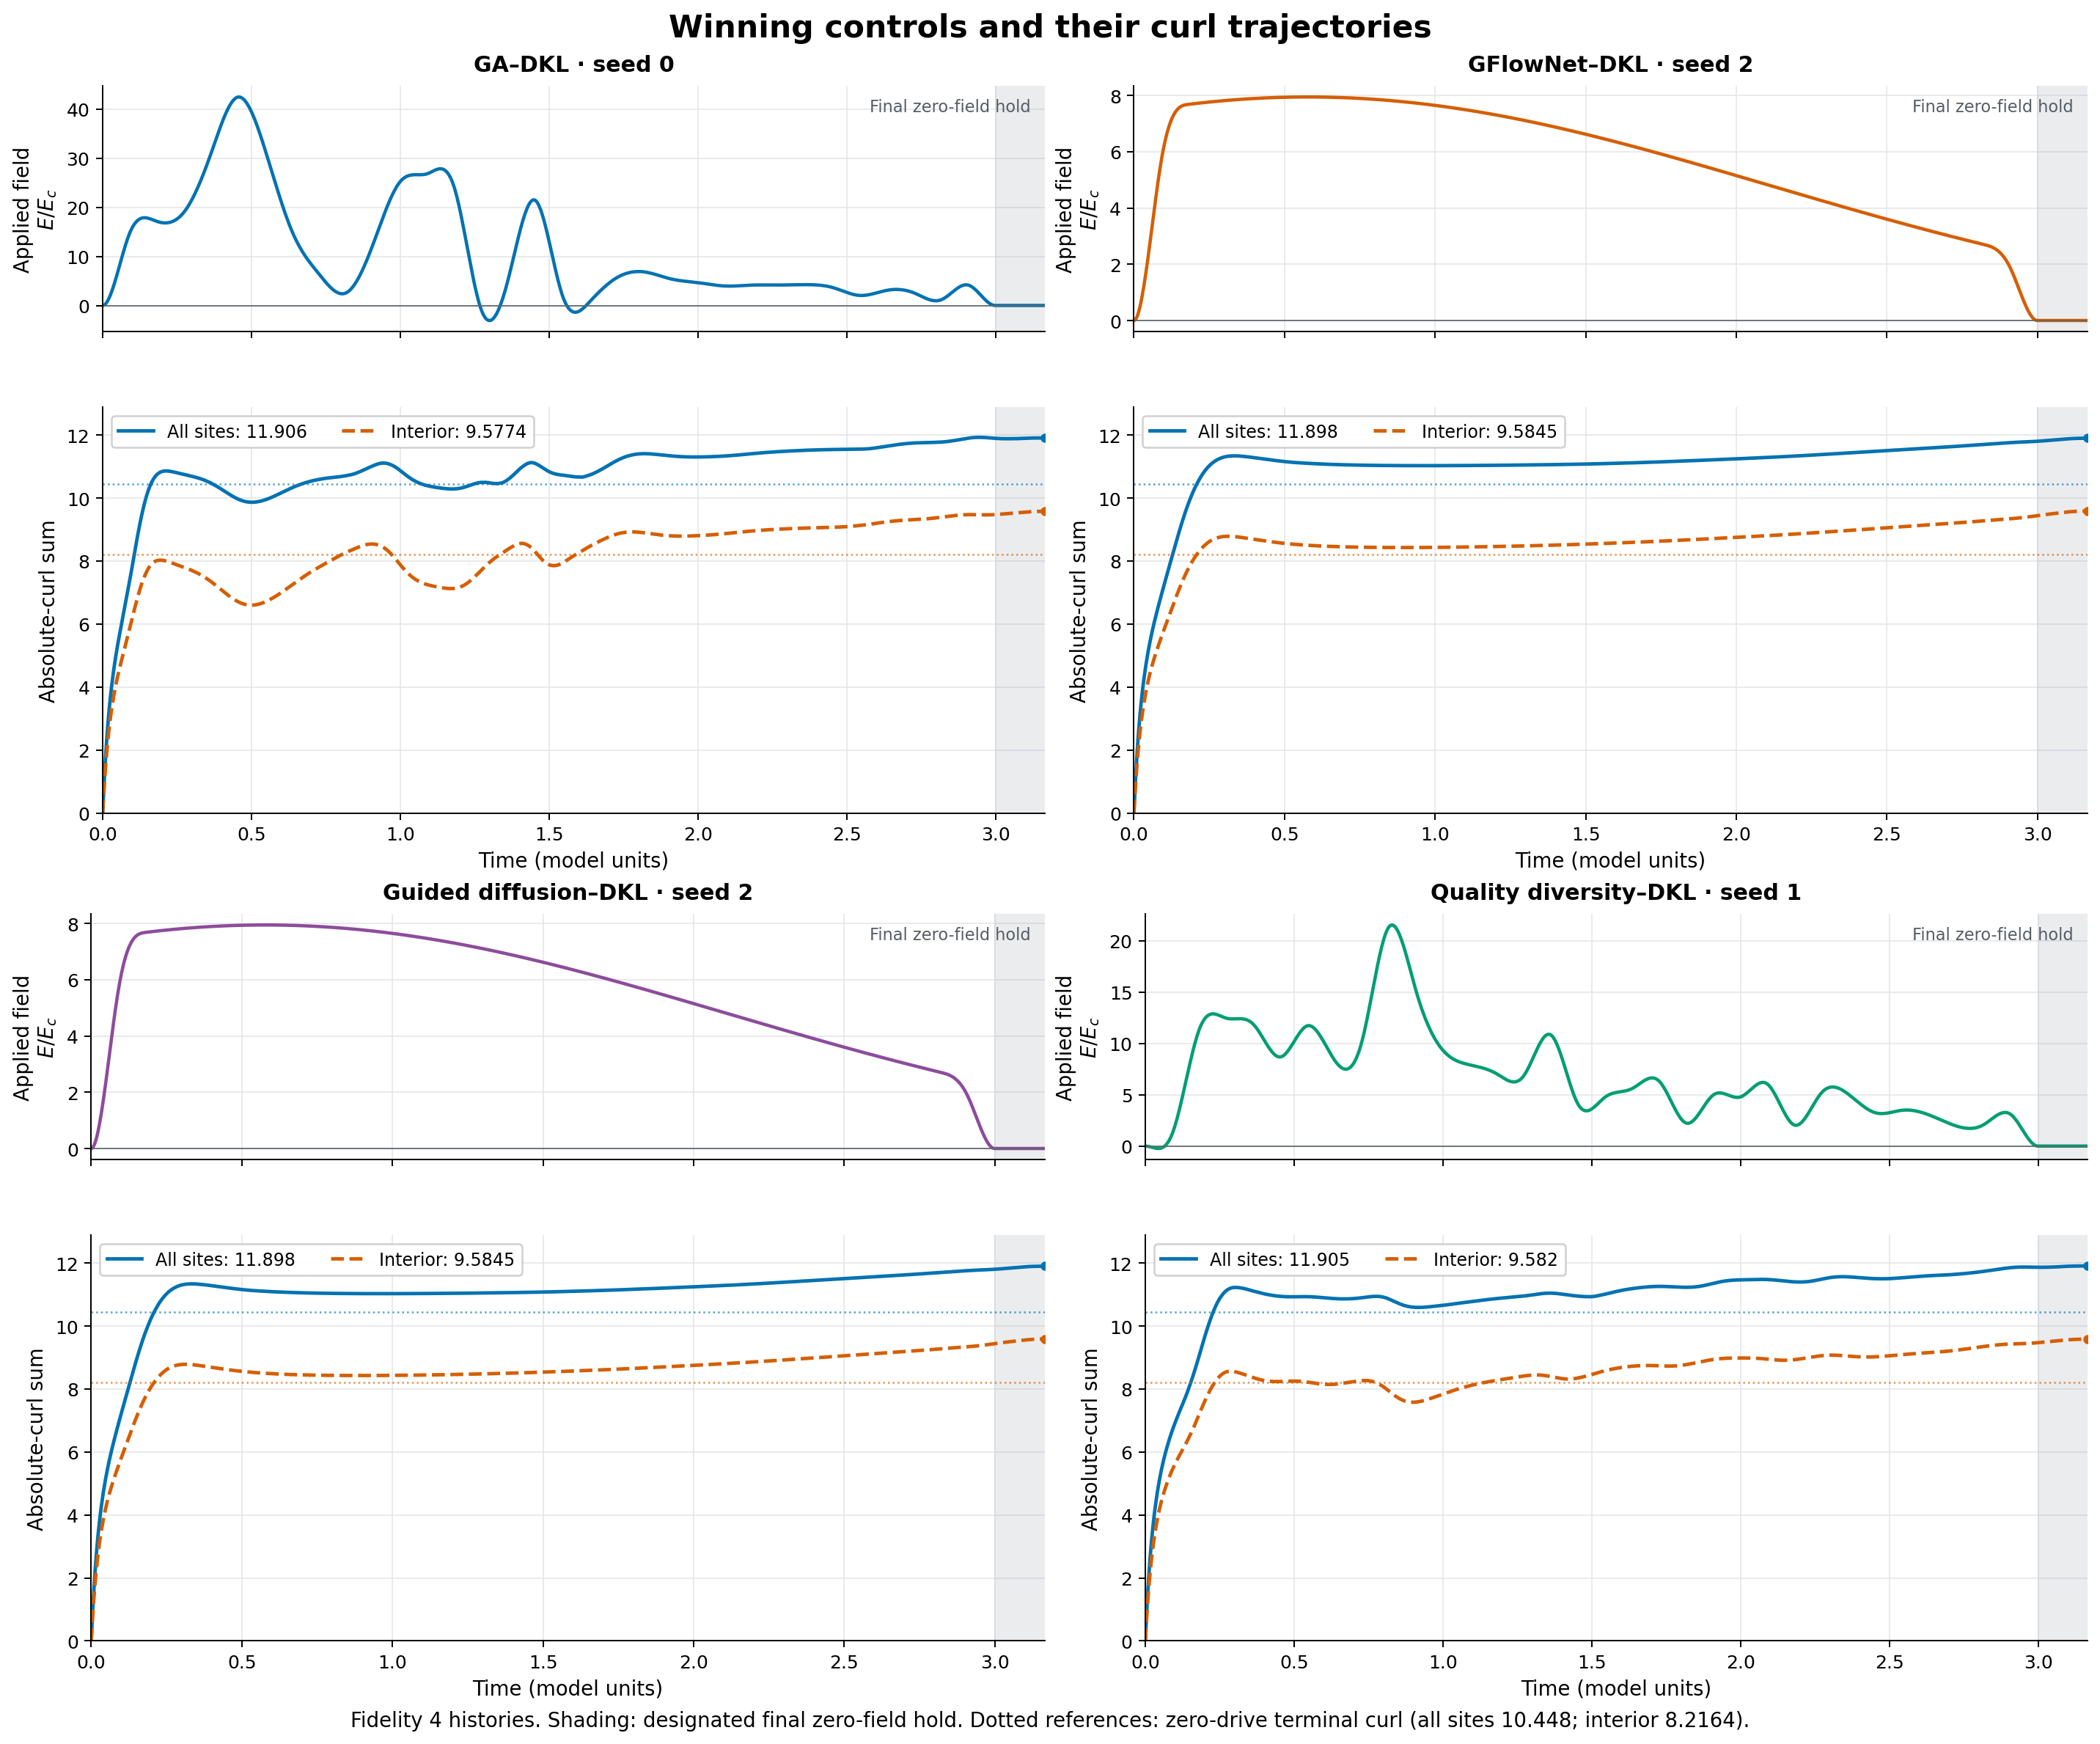

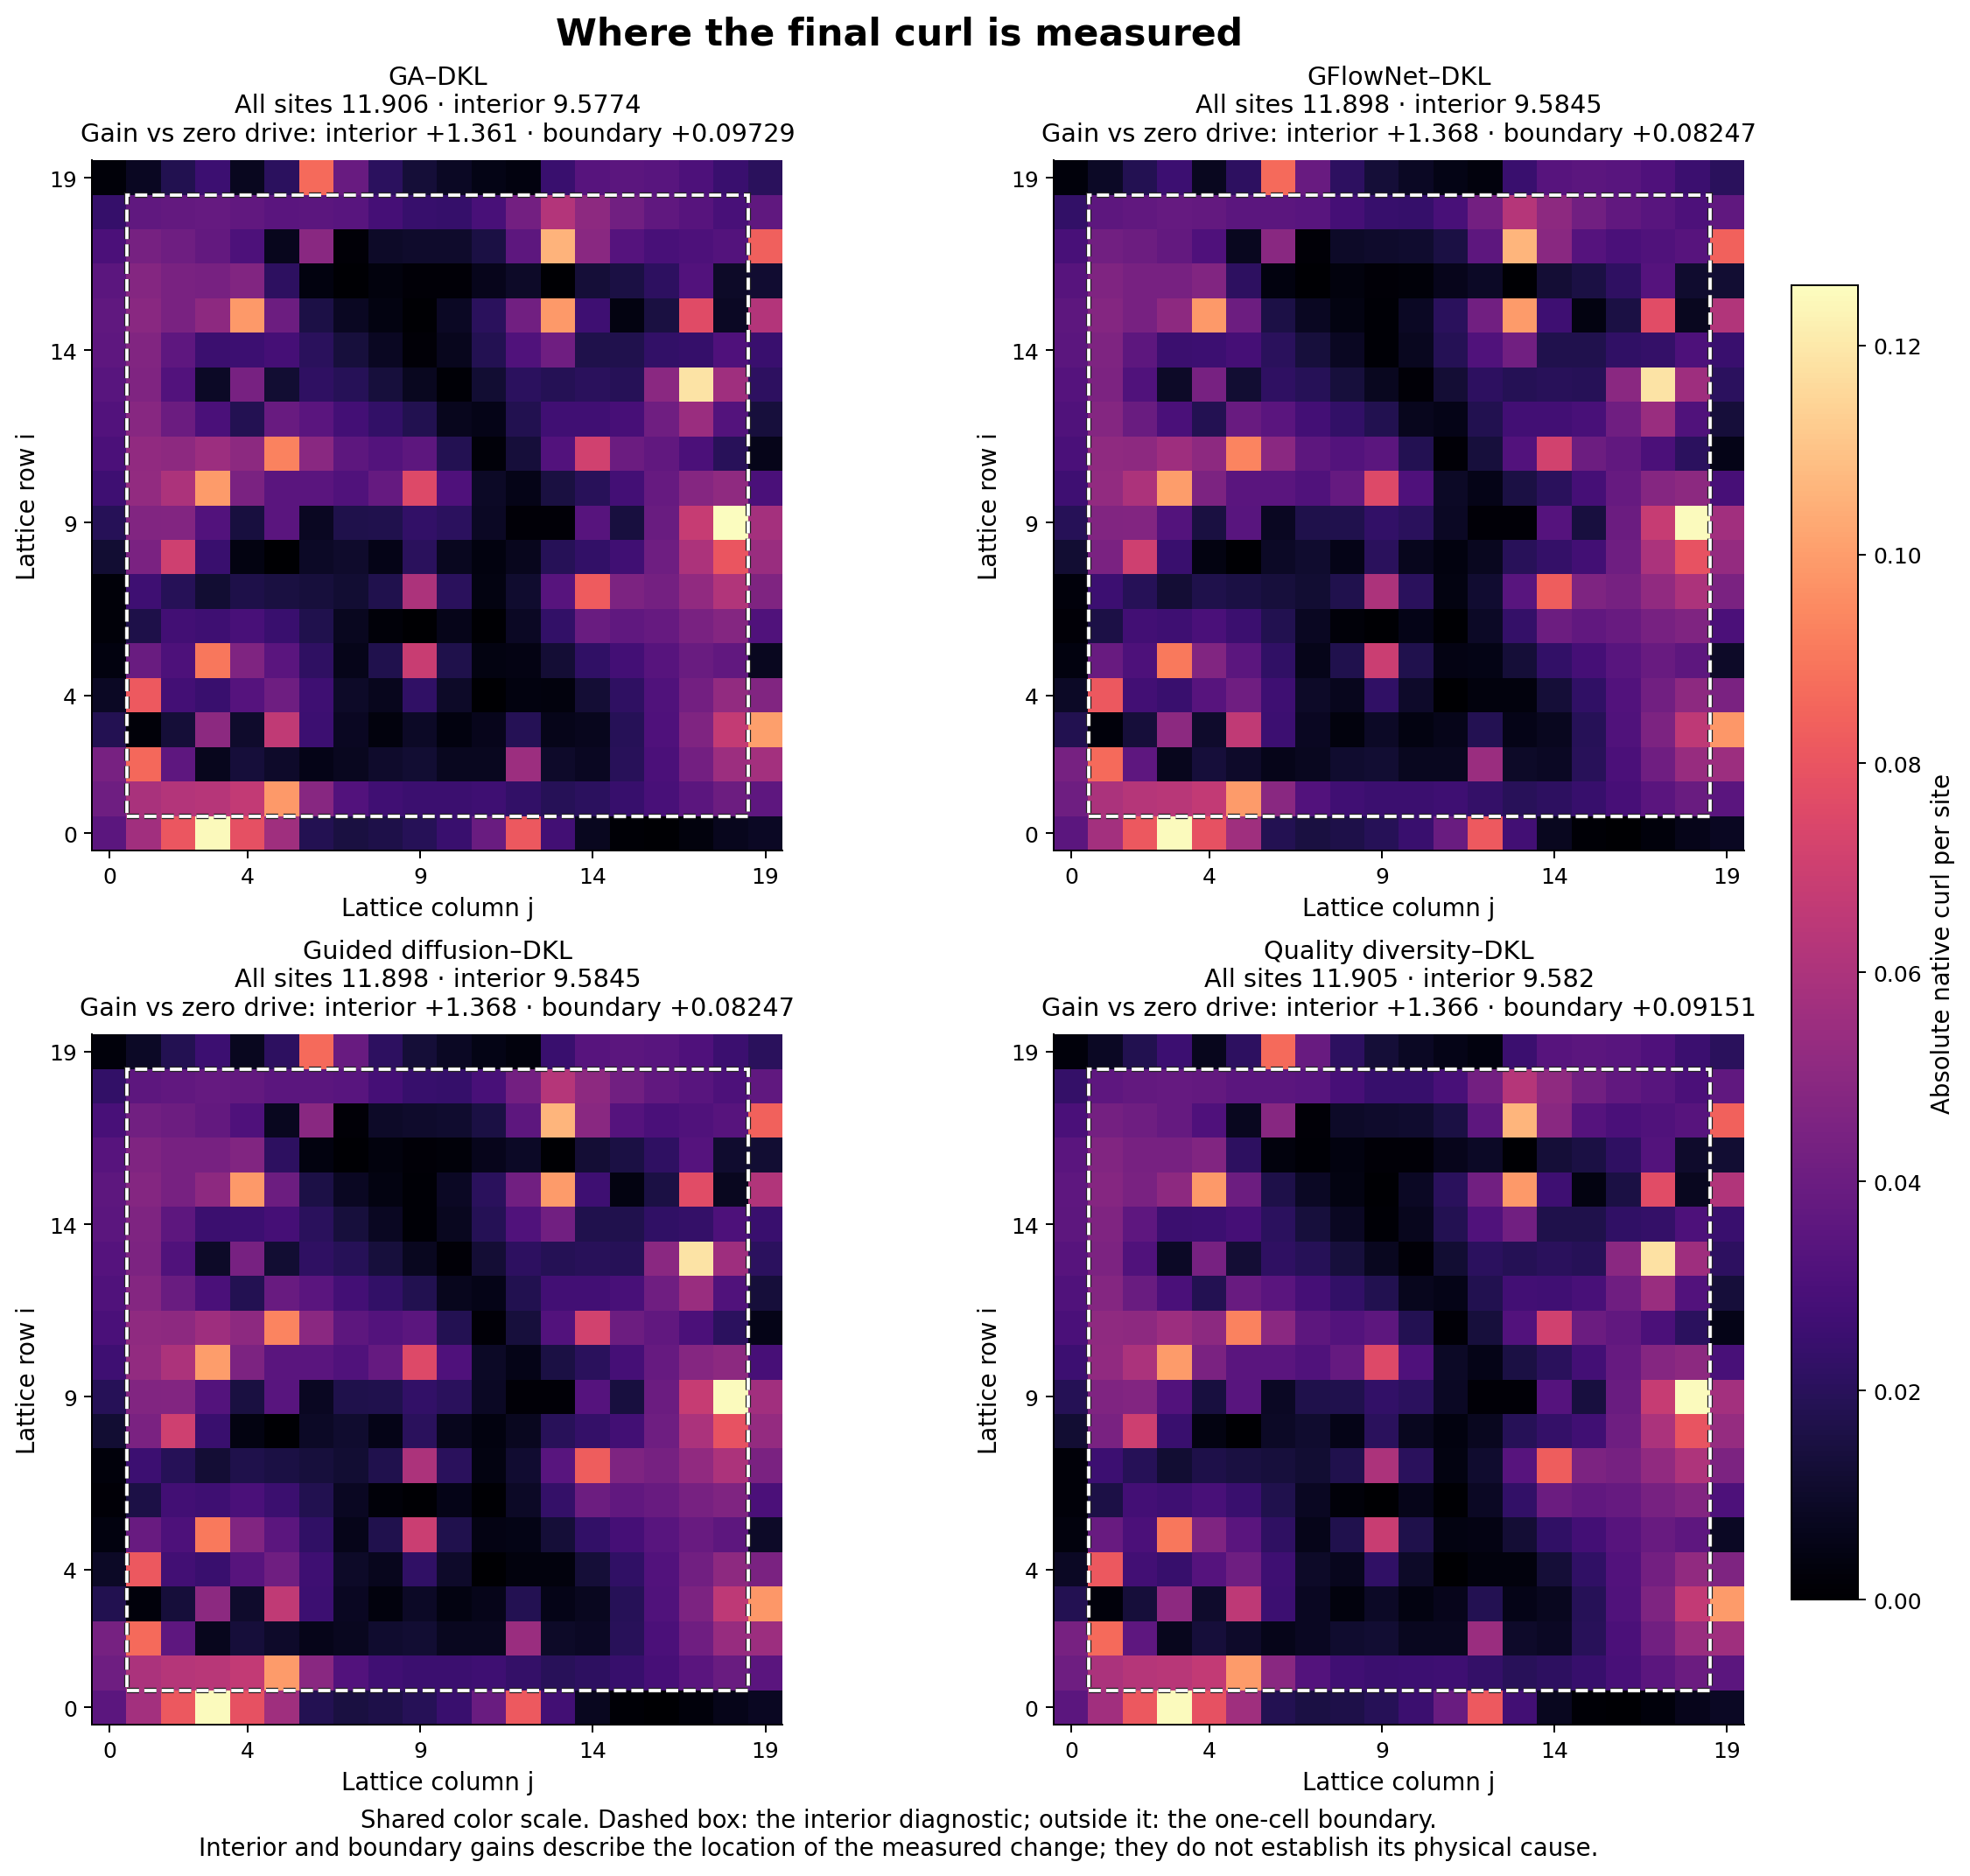

In [17]:
if VALIDATION is not None:
    show_figure('winner_physics_histories', group='physics')
    show_figure('winner_curl_spatial_maps', group='physics')

### Large-amplitude behavior

Removing an amplitude cap does not require curl to vanish at high field.
The readout occurs after a zero-field hold in a model with fixed defects.
The direct amplitude sweep below shows the measured terminal behavior;
no monotonic falloff or vanishing limit was imposed. Each scaled waveform
was evaluated as supplied and retains its numerical and guard flags.

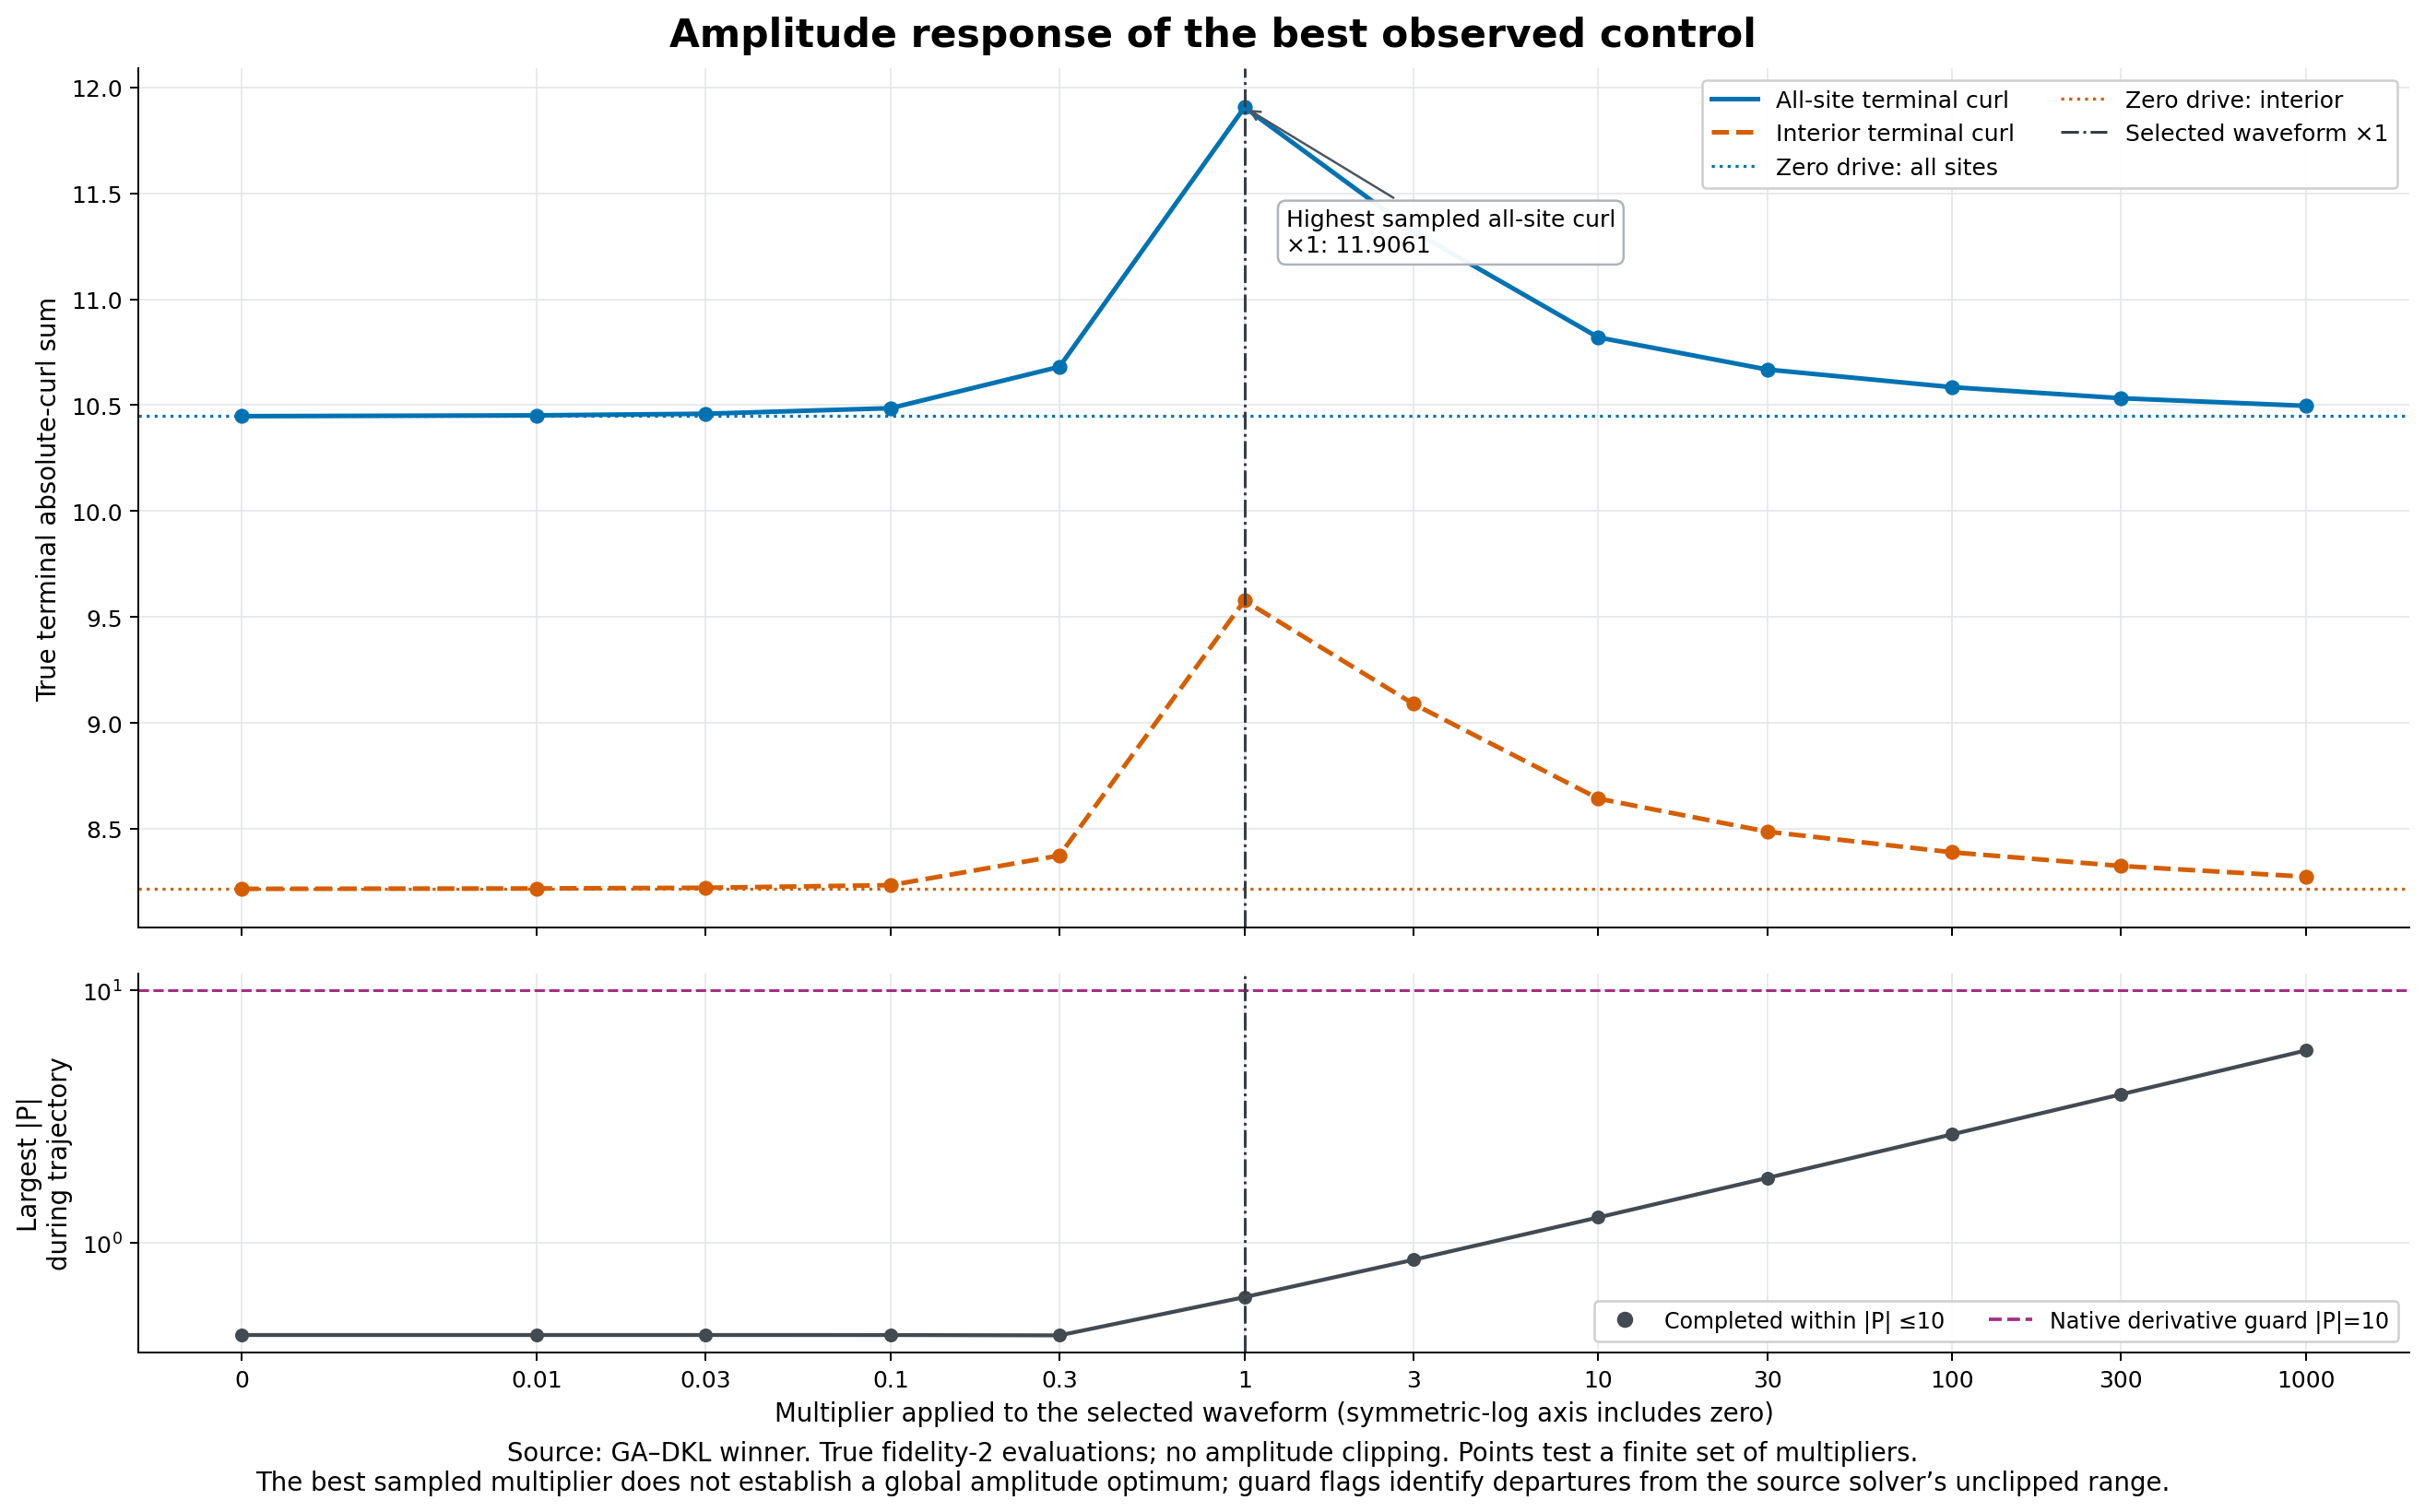

,scale_factor,source_candidate_id,curl,interior_curl,max_abs_P,native_guard_exceeded,status,valid,rhs_calls,substeps,field_peak_ec_sampled,fidelity,complexity8193,dense_peak_ec,dense_rms_ec
0,0.00,candidate_0005,10.447895713,8.216424303,0.432136701,False,0,True,18980,4745,0.000000000,2,0,0.000000000,0.000000000
1,0.01,candidate_0005,10.451737443,8.218121451,0.432135904,False,0,True,18980,4745,0.424827883,2,13,0.424834646,0.152640350
2,0.03,candidate_0005,10.459337653,8.221525168,0.432129507,False,0,True,18980,4745,1.274483648,2,13,1.274503938,0.457921051
3,0.10,candidate_0005,10.485640387,8.233787155,0.432052277,False,0,True,18980,4745,4.248278827,2,13,4.248346461,1.526403502
4,0.30,candidate_0005,10.681044111,8.373634975,0.430767887,False,0,True,18980,4745,12.744836481,2,13,12.745039383,4.579210507
5,1.00,candidate_0005,11.906135761,9.577377440,0.610465851,False,0,True,19160,4790,42.482788271,2,13,42.483464610,15.264035022
6,3.00,candidate_0005,11.321316719,9.089852771,0.857822925,False,0,True,20236,5059,127.448364813,2,13,127.450393830,45.792105066
7,10.00,candidate_0005,10.819701315,8.642473598,1.263046687,False,0,True,23520,5880,424.827882710,2,13,424.834646100,152.640350219
8,30.00,candidate_0005,10.668204143,8.486432372,1.810084985,False,0,True,29160,7290,1274.483648131,2,13,1274.503938300,457.921050657
9,100.00,candidate_0005,10.584767906,8.388830142,2.694973755,False,0,True,44496,11124,4248.278827103,2,13,4248.346460999,1526.403502190


In [18]:
if VALIDATION is not None:
    show_figure('winner_amplitude_response', group='physics')
    display(pd.read_csv(VALIDATION / 'winner_amplitude_sweep.csv'))

## 9. Stopping, provenance, and scope

The original study used matched extensions through 32 generations. A
preceding-eight-generation gain of 0.1% in best curl or 0.5% in Pareto
hypervolume would have triggered another block. No run triggered either
criterion at the final endpoint. This practical stopping rule does not
certify a global optimum in an unbounded 32-dimensional space.

The methods use fixed implementations and training budgets. The diffusion
pipeline is a continuous guided-diffusion adaptation, and QD is inspired
by surrogate-assisted illumination. These results are not a claim to
reproduce LaMBO-2 or to establish a universal ranking of algorithm families.

A separate disorder study would require new spline simulations, a
map-aware run/cache identity, and independent evaluation accounting. The
measured baseline here must not be relabeled as such a study.

In [19]:
stopping = original_analysis['stopping_diagnostic']
display(pd.DataFrame({k: v for k, v in stopping.items() if not isinstance(v, list)}.items(),
                     columns=['Stopping diagnostic', 'Value']))
provenance = table('method_comparison')[[
    'method_label', 'own_proposer_seed_winners', 'common_prior_seed_winners',
    'own_proposer_exceeded_initialization_runs', 'runs']]
display(provenance)
portability = ROOT / 'validation/portability/portability_validation.json'
if portability.exists():
    check = json.loads(portability.read_text())
    display(pd.DataFrame({key: check[key] for key in (
        'all_passed', 'new_physical_evaluations', 'archived_rows',
        'all_rows_valid', 'completed_output_skip_spent_zero_queries',
        'historical_archives_unchanged')}.items(), columns=['Fresh portability check', 'Result']))

,Stopping diagnostic,Value
0,window_generations,8
1,best_curl_relative_gain_threshold,0.001
2,hypervolume_relative_gain_threshold,0.005
3,comparison_operator,>=
4,any_run_meets_extension_threshold,False
5,all_expected_runs_present,True
6,all_runs_at_same_generation,True
7,all_runs_have_sufficient_window,True
8,decision_ready,True
9,recommended_action,no_extension_triggered_by_the_prespecified_imp...


,method_label,own_proposer_seed_winners,common_prior_seed_winners,own_proposer_exceeded_initialization_runs,runs
0,GA–DKL,3,0,3,3
1,GFlowNet–DKL,0,3,0,3
2,Guided diffusion–DKL,0,3,0,3
3,Quality diversity–DKL,3,0,3,3


,Fresh portability check,Result
0,all_passed,True
1,new_physical_evaluations,192
2,archived_rows,384
3,all_rows_valid,True
4,completed_output_skip_spent_zero_queries,True
5,historical_archives_unchanged,True


In [20]:
if SHOW_SUPPLEMENTARY:
    for name in ('pareto_pooled', 'pareto_front_history', 'best_waveforms',
                 'champion_waveform_history', 'pareto_waveforms'):
        show_figure(name, group='original')
integrity_after = verify_inputs(ROOT)
assert integrity_before == integrity_after
print(f"All {integrity_after['verified_files']} frozen inputs are unchanged after execution.")
print('New simulator queries: search =', new_search_queries,
      '; validation =', new_validation_queries,
      '; total =', new_search_queries + new_validation_queries)
print('Tables:', TABLES.relative_to(ROOT))
print('Figures:', FIGURES.relative_to(ROOT))

All 111 frozen inputs are unchanged after execution.
New simulator queries: search = 0 ; validation = 0 ; total = 0
Tables: tables
Figures: figures


## Source record and exported files

**Local evidence:** `protocol.json`, `provenance/archive_audit.json`,
`provenance/spline_import.json`, and the per-run configuration/diagnostic
files identify the settings and source hashes. `provenance/notebook_inputs.json`
protects the supplied scientific inputs. Historical metadata may retain
original absolute paths as provenance; execution resolves bundled files
relative to this notebook.

**Main exports:** `tables/study/method_comparison.csv`,
`query_target_summary.csv`, `query_to_target.csv`, `evaluation_progress.csv`,
`pooled_historical_front.csv`, `fronts_by_generation.csv`,
`selected_controls.json`, and `selected_waveforms.csv`. Figures are saved
as both PNG and vector PDF.

**Pinned upstream sources:**

- [FerroSim historical equations](https://github.com/ramav87/FerroSim/tree/5eb258e2a47d10b3d9bdb9e94dd9879b8410024c).
- [GA–DKL defect data](https://github.com/saimani5/GA-DKL/tree/7534a14c121aed372342051e79639f243c9d1b32).

The fresh four-method, one-generation verification is recorded in
`validation/portability/portability_validation.json`; its 192 new queries
are separate from the historical search and from default notebook replay.

The original source narrative and literature references are preserved in
`provenance/original_README.md`; the earlier results narrative is in
`provenance/original_RESULTS.md`. Measured histories, not literature claims,
support the numerical conclusions in this notebook.